# Partis et dirigeants : les caractéristiques du parti et de son dirigeant apportent-elles une information sur la survie des partis autoritaires ?
*Fedi Jouili*

**Objectif.** Les modèles de Cox de `final_panel.ipynb` expliquent la durée de vie des partis autoritaires par leur origine, leur stratégie de gouvernance, leur idéologie, le niveau démocratique et le conflit armé (et, dans le modèle time-varying, le PIB par habitant). Ce notebook teste si sept caractéristiques **du parti et de son dirigeant** apportent une information au-delà de ces covariables : l'âge du parti quand il arrive au pouvoir, l'âge du dirigeant, son arrivée au pouvoir de façon irrégulière, son service militaire, son passé dans un groupe rebelle, ses études universitaires et son expérience politique avant le pouvoir.

Il reprend le protocole et les règles de `04_demographics.ipynb` et de `05_shocks.ipynb`, dans les deux tâches : **Tâche A** (durée au pouvoir ; valeur à l'entrée au pouvoir ; modèle de Cox statique) et **Tâche B** (chute dans l'année ; valeur de l'année précédente ; modèle de Cox time-varying). Les sept variables forment un seul bloc et une famille de correction de Holm distincte de celles des notebooks 04 et 05, dont les résultats ne changent pas.

**Ce que ce notebook ne fait pas.** Il ne modifie aucun résultat existant : les données, modèles et exports de `final_panel.ipynb`, `03_ml_survival.ipynb`, `04_demographics.ipynb` et `05_shocks.ipynb` sont lus, jamais réécrits ; le modèle du site et la simulation ne changent pas. Les variables, leur mesure et les règles de décision ont été fixées et validées avant tout résultat (Sections 3 et 5).

**Précautions.** Contrairement à celles des notebooks 04 et 05, ces variables décrivent le parti ou son dirigeant, pas le pays : une variable retenue pourrait devenir un choix de la simulation, mais seulement si cela est explicitement accepté après la lecture des résultats. Les résultats décrivent des associations, pas des causes.

## Plan du notebook
0. Configuration
1. Sources des données
2. Table des dirigeants à l'entrée au pouvoir (revue à la main)
3. Construction des variables
4. Fusion avec les jeux des modèles, couverture et colinéarité
5. Règles de décision (fixées avant les résultats)
6. Modèles estimés sur les échantillons communs (hazard ratios)
7. Validation croisée (prédiction)
8. Décision et modèle final
9. Conclusion et limites
10. Export des résultats
11. Références

## 0. Configuration

In [1]:
# ============================================================
# 0. Configuration et imports
# ============================================================
import hashlib
import json
import sys
import time
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from lifelines import CoxPHFitter, CoxTimeVaryingFitter
from lifelines.statistics import proportional_hazard_test
from scipy import stats
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sksurv.metrics import concordance_index_censored, concordance_index_ipcw, integrated_brier_score
from sksurv.util import Surv
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
ALPHA = 0.05
PENALIZER = 0.01          # même spécification que final_panel.ipynb, 03_ml_survival.ipynb, 04 et 05
N_FOLDS, N_REPEATS, N_INNER = 5, 10, 3
MIN_FALLS = 120           # une variable doit laisser au moins 120 chutes, dans chacune des deux tâches
MIN_EPP = 10              # aucun modèle n'est estimé avec moins de 10 chutes par paramètre
CUT = 10                  # seuil des effets précoces / tardifs (final_panel.ipynb, section 6)
ARCHIGOS_LAST_YEAR = 2015                           # Archigos 4.1 s'arrête au 31 décembre 2015
RULES_WRITTEN, RULES_APPROVED = "2026-10-21", "2026-10-23"

# Racine du projet : fonctionne que le notebook soit lancé depuis la racine ou depuis notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
assert (PROJECT_ROOT / "data").is_dir(), f"Racine du projet introuvable depuis {Path.cwd()}"
RAW, PROC = PROJECT_ROOT / "data" / "raw", PROJECT_ROOT / "data" / "processed"
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from panel_model import late_hazard_ratios, split_early_late   # correction de final_panel.ipynb (section 6.3)
from site_export import write_json

## 1. Sources des données

| Variables | Source | Version | Fichier | Citation | Conditions d'utilisation |
|---|---|---|---|---|---|
| `leader_military`, `leader_rebel`, `leader_university`, `leader_experience` | LEAD (*Leader Experience and Attribute Descriptions*), reprise sans recodage par le paquet R `peacesciencer` | LEAD v1 (1875-2004) ; fichier `data/LEAD.rda` du commit `2bb33211` (22 mars 2023) | `data/raw/lead/LEAD.rda`, converti en `LEAD.csv` | Ellis, Horowitz & Stam (2015) ; Miller (2022) | aucune licence indiquée pour les données (paquet sous GPL-2) : **pas de redistribution** |
| `leader_age`, `leader_irregular` ; dirigeant de chaque année | Archigos (dirigeants effectifs) | 4.1 (jusqu'au 31 décembre 2015), version annuelle | `data/raw/arch_annual.csv` | Goemans, Gleditsch & Chiozza (2009) | aucune licence indiquée ; citation demandée |
| `party_age` | ARPD (année de fondation du parti) | panel du projet | `data/processed/arpd_panel_merged.csv` | Miller (2020) | |
| lien parti → dirigeant | table revue à la main (Section 2) | 23 octobre 2026 | `data/raw/arpd_leaders_archigos.csv` | | |
| contrôle du PIB | Maddison (déjà dans le panel) | 2023 | `data/processed/arpd_panel_merged.csv` | Bolt & van Zanden (2024) | CC BY 4.0 |

**Téléchargement.** LEAD n'a pas de page de téléchargement propre : ses variables sont diffusées par le paquet `peacesciencer`. Le script `src/download_party_leader_data.py` télécharge `LEAD.rda` depuis le dépôt GitHub du paquet, à un commit figé, le convertit en CSV (`pyreadr`) et enregistre l'adresse, la date, la version, la licence, la taille et l'empreinte SHA-256 de chaque fichier dans `data/raw/party_leader_sources.json`. Il lit d'abord le `robots.txt` du serveur, envoie une requête à la fois, respecte `Retry-After` et ne remplit aucun formulaire ; un fichier dont l'empreinte change l'arrête. Ce notebook le lance si LEAD manque, puis vérifie les empreintes.

**Sources écartées à l'étape de contrôle** (21 octobre 2026, enregistrées dans le même fichier) : V-Party (téléchargement derrière un formulaire, et au plus 106 chutes à l'entrée au pouvoir), DPI 2023 (au plus 99) et PLAD (au plus 68) ne peuvent pas atteindre les 120 chutes exigées à l'entrée, même parfaitement reliés.

`data/raw/lead/` et les tables de `data/processed/` qui contiennent des valeurs de LEAD (`ml_static_leaders.csv`, `ml_timevarying_leaders.csv`) sont exclus du dépôt par `.gitignore`. L'export (Section 10) ne contient que des tableaux de résultats.

In [2]:
# ============================================================
# 1. Fichiers sources : téléchargement (script séparé) et vérification des empreintes
# ============================================================
SOURCES_LOG = RAW / "party_leader_sources.json"
LEAD_DIR = RAW / "lead"
if not (LEAD_DIR / "LEAD.rda").exists() or not (LEAD_DIR / "LEAD.csv").exists() or not SOURCES_LOG.exists():
    import download_party_leader_data      # robots.txt, une requête à la fois, Retry-After, aucun formulaire
    download_party_leader_data.main()
log = json.loads(SOURCES_LOG.read_text(encoding="utf-8"))
for name, path in (("LEAD.rda", LEAD_DIR / "LEAD.rda"), ("arch_annual.csv", RAW / "arch_annual.csv")):
    assert hashlib.sha256(path.read_bytes()).hexdigest() == log[name]["sha256"], f"{name} a changé depuis son enregistrement"

files = pd.DataFrame([{"fichier": n, "date": log[n]["downloaded"][:10], "octets": log[n]["bytes"],
                       "sha256": log[n]["sha256"][:12] + "…", "années": log[n]["années"]}
                      for n in ("LEAD.rda", "arch_annual.csv")]).set_index("fichier")
display(files)
print("LEAD :", log["LEAD.rda"]["url"])
not_used = pd.DataFrame(log["sources_non_utilisées"]).T[["formulaire", "version", "licence", "années", "raison"]]
display(Markdown("**Sources candidates non utilisées** (étape de contrôle) :"))
display(not_used)

,date,octets,sha256,années
fichier,,,,
LEAD.rda,2026-10-23,14388,91c91901b7fa…,1875-2004
arch_annual.csv,déjà dans,3203982,07d65eef00fb…,1840-2015


LEAD : https://raw.githubusercontent.com/svmiller/peacesciencer/2bb332117051fc00cbaaadde9a7470274a419119/data/LEAD.rda


**Sources candidates non utilisées** (étape de contrôle) :

,formulaire,version,licence,années,raison
V-Party v2,oui : le téléchargement demande une adresse e-...,"v2, février 2022",non indiquée sur la page,"1970-2019 (variables codées par des experts), ...","non testable : même parfaitement relié, au plu..."
DPI 2023,"non : liens directs (CSV, XLSX)","DPI 2023, publiée le 11 mars 2026 (https://doi...",Creative Commons Attribution 4.0,1975-2023,non testable : au plus 99 chutes à l'entrée au...
PLAD v7,"non : Harvard Dataverse, sans questionnaire ni...","7, avril 2024",CC0 1.0,1989-2023,non testable : au plus 68 chutes à l'entrée au...


## 2. Table des dirigeants à l'entrée au pouvoir (revue à la main)

Pour la Tâche A, chaque parti du modèle statique est relié au dirigeant qui l'a mené au pouvoir, dans `data/raw/arpd_leaders_archigos.csv` (224 lignes : `spell_id`, `entry_year`, `ccode`, `obsid`, `leader`, `leader_start`, `review`, `note`).

* **Lien automatique** : le dirigeant effectif d'Archigos en fonction au 31 décembre de l'année d'entrée au pouvoir (s'il n'y en a pas, le dernier de l'année). Les codes pays de l'ARPD sont traduits en codes COW comme dans `05_shocks.ipynb`, puis en codes d'Archigos, qui garde 678 pour le Yémen unifié (679 dans COW).
* **Revue à la main** (23 octobre 2026), avec Archigos et Wikipédia (dates de prise de fonction), de toutes les lignes, en particulier les 102 partis dont le dirigeant était au pouvoir avant le parti, les 83 années d'entrée avec plusieurs dirigeants et les trois monarchies. Le lien va au dirigeant qui a mené le parti au pouvoir : (1) le chef du parti, s'il est un dirigeant d'Archigos à l'arrivée du parti (l'année d'entrée ou la suivante) ; (2) sinon le dirigeant qui a créé le parti ou en a fait le parti au pouvoir, ou le chef du coup d'État qui l'a installé ; (3) sinon, pas de lien : les dirigeants effectifs de l'époque appartenaient à un autre camp ou à aucun.
* `review` vaut « vérifié » (lien automatique confirmé) ou « corrigé » (autre dirigeant, ou pas de lien) ; `note` en donne la raison.

In [3]:
# ============================================================
# 2. Table des dirigeants à l'entrée au pouvoir
# ============================================================
ARPD_TO_COW = {364: 365, 818: 816, 529: 530, 347: 345, 624: 625, 769: 770}   # 05_shocks.ipynb, section 2.1
COW_TO_ARCHIGOS = {679: 678}                                                   # Yémen unifié


def archigos_code(cow):
    return COW_TO_ARCHIGOS.get(cow, cow)


arch = pd.read_csv(RAW / "arch_annual.csv", low_memory=False)
arch["year"] = arch["startdate"].str[:4].astype(int)
LEADERS = (arch.sort_values("startdate").groupby("obsid")
               .agg(leader=("leader", "first"), ccode=("ccode", "first"), start=("startdate", "first"),
                    entry=("entry", "first"), yrborn=("yrborn", "first")))
LEADERS["yrborn"] = pd.to_numeric(LEADERS["yrborn"], errors="coerce")
arch["dec31"] = arch["enddate"].str[5:] == "12-31"
DEC31 = (arch.sort_values(["ccode", "year", "dec31", "startdate"]).groupby(["ccode", "year"]).tail(1)
             .set_index(["ccode", "year"])["obsid"])          # dirigeant au 31 décembre (sinon le dernier de l'année)

meta = json.loads((PROC / "ml_metadata.json").read_text(encoding="utf-8"))
SF, TF = meta["static"]["features"], meta["timevarying"]["features"]
static = pd.read_csv(PROC / meta["static"]["file"])
tv = pd.read_csv(PROC / meta["timevarying"]["file"])
assert (len(static), int(static["event"].sum())) == (meta["static"]["rows"], meta["static"]["events"])
assert (len(tv), int(tv["event"].sum())) == (meta["timevarying"]["rows"], meta["timevarying"]["events"])

panel = pd.read_csv(PROC / "arpd_panel_merged.csv", low_memory=False)
panel = panel[panel["Party"] != "N"].copy()                         # juntes exclues, comme dans final_panel.ipynb
panel["spell_id"] = panel["Country"] + "_" + panel["Party"] + "_" + panel["Year in Power"].astype("Int64").astype(str)
first = panel.sort_values("panel_year").drop_duplicates("spell_id").set_index("spell_id")
COW = {s: ARPD_TO_COW.get(int(c), int(c)) for s, c in first["ccode"].items()}
assert panel.groupby("spell_id")["ccode"].nunique().max() == 1

links = pd.read_csv(RAW / "arpd_leaders_archigos.csv", keep_default_na=False)
assert links["spell_id"].is_unique and set(links["spell_id"]) == set(static["spell_id"]), "une ligne par parti"
assert links["review"].isin(["vérifié", "corrigé"]).all() and (links["note"] != "").all()
assert (links["ccode"] == links["spell_id"].map(lambda s: archigos_code(COW[s]))).all()
linked = links[links["obsid"] != ""]
assert linked["obsid"].isin(LEADERS.index).all()
assert (linked["leader_start"] == LEADERS.loc[linked["obsid"], "start"].to_numpy()).all()

links["automatique"] = [DEC31.get((c, int(y)), "") for c, y in zip(links["ccode"], links["entry_year"])]
LINK_STATS = {"spells": len(links), "automatic_found": int((links["automatique"] != "").sum()),
              "automatic_confirmed": int((links["automatique"] == links["obsid"]).sum()),
              "other_leader": int(((links["obsid"] != "") & (links["obsid"] != links["automatique"])).sum()),
              "no_link": int((links["obsid"] == "").sum()), "reviewed": int(links["review"].isin(["vérifié", "corrigé"]).sum())}
assert LINK_STATS["automatic_confirmed"] + LINK_STATS["other_leader"] + LINK_STATS["no_link"] == len(links)
display(Markdown(
    f"**Table des dirigeants** : {LINK_STATS['spells']} partis, tous revus. Lien automatique trouvé pour "
    f"{LINK_STATS['automatic_found']} partis, confirmé pour {LINK_STATS['automatic_confirmed']} "
    f"({LINK_STATS['automatic_confirmed'] / len(links):.0%}) ; corrigé pour {LINK_STATS['other_leader']} "
    f"(autre dirigeant) ; pas de lien pour {LINK_STATS['no_link']}."))


def who(obsid):
    return f"{LEADERS.loc[obsid, 'leader']} ({obsid})" if obsid else "pas de lien"


corrected = links[links["review"] == "corrigé"].assign(
    **{"lien automatique": lambda d: d["automatique"].map(who), "lien retenu": lambda d: d["obsid"].map(who)})
with pd.option_context("display.max_colwidth", 160):
    display(corrected[["spell_id", "entry_year", "lien automatique", "lien retenu", "note"]].set_index("spell_id"))

**Table des dirigeants** : 224 partis, tous revus. Lien automatique trouvé pour 224 partis, confirmé pour 209 (93%) ; corrigé pour 9 (autre dirigeant) ; pas de lien pour 6.

,entry_year,lien automatique,lien retenu,note
spell_id,,,,
"Armenia_Republican Party of Armenia (RPA, or HHK)_1999",1999,Kocharian (ARM-1998),pas de lien,"pas de lien : Archigos retient Kotcharian, président sans parti ; le RPA arrive au pouvoir par les législatives de 1999 avec Vazgen Sargsian, Premier minist..."
Benin_Dahomeyan Democratic Party_1963,1963,Soglo (BEN-1963),Apithy (BEN-1964),"Archigos retient le colonel Soglo (intérim d'octobre 1963 à janvier 1964) ; le PDD, fondé le 15 décembre 1963 par Apithy et Ahomadégbé, porte Apithy à la pr..."
Czechoslovakia_Communist Party of Czechoslovakia_1947,1947,Benes (CZE-1945),Gottwald (CZE-1948),"Archigos retient Beneš (président, non communiste) en 1947 ; le parti est mené au pouvoir par Gottwald, Premier ministre depuis 1946, président en juin 1948..."
El Salvador_Nationalist Republican Alliance (ARENA)_1981,1981,Duarte (SAL-1980),pas de lien,"pas de lien : Archigos retient Duarte (démocrate-chrétien, adversaire d'ARENA), puis Magaña (sans parti) ; le chef d'ARENA, D'Aubuisson, n'est pas un dirige..."
Guinea-Bissau_African Party for the Independence of Guinea and Cape Verde (PAIGC)_2004,2004,Henrique Pereira Rosa (GNB-2003-2),pas de lien,"pas de lien : Archigos retient Henrique Rosa, président de transition sans parti ; le PAIGC revient au pouvoir par les législatives de 2004 avec Carlos Gome..."
Latvia_Communist Party of Latvia_1991,1991,Godmanis (LAT-1990),pas de lien,"pas de lien : Archigos retient Godmanis, chef du gouvernement du Front populaire, adversaire du Parti communiste"
Lithuania_Communist Party of Lithuania_1991,1991,Landsbergis (LIT-1990),pas de lien,"pas de lien : Archigos retient Landsbergis (Sąjūdis), adversaire du Parti communiste"
Myanmar_Union Solidarity and Development Party_2010,2010,Than Shwe (MYA-1992),Thein Sein (MYA-2011),"Archigos retient Than Shwe, chef de la junte qui crée le parti ; son président, Thein Sein, prend la tête de l'État en mars 2011 après les élections de nove..."
Republic of Congo_Democratic Union for the Defence of African Interests_1963,1963,Debat (CON-1963),Youlou (CON-1960),"Archigos retient Massamba-Débat, arrivé après la chute de l'UDDIA en août 1963 ; le chef de l'UDDIA est Youlou (lien automatique remplacé : CON-1963, Debat)"


## 3. Construction des variables

Les variables, leur mesure et leurs unités ont été fixées à l'étape de contrôle (21 octobre 2026) et validées le 23 octobre 2026, avant tout résultat.

| Variable | Définition | Source | Tâche A (entrée au pouvoir) | Tâche B (année précédente) | Unité du hazard ratio |
|---|---|---|---|---|---|
| `party_age` | âge du parti quand il arrive au pouvoir : année d'entrée − année de fondation | ARPD | à l'entrée | la même valeur : sur l'échelle du temps au pouvoir, l'âge de l'année précédente (âge à l'entrée + temps au pouvoir) donne le même coefficient | 10 ans de plus |
| `leader_age` | âge du dirigeant : année − année de naissance | Archigos | dirigeant de la table (Section 2), l'année d'entrée | dirigeant de l'année précédente, cette année-là | 10 ans de plus |
| `leader_irregular` | le dirigeant est arrivé au pouvoir de façon irrégulière (coup d'État, révolte, assassinat…) : mode d'entrée « Irregular » d'Archigos ; « Regular » et « Foreign Imposition » valent 0, « Unknown » est manquant | Archigos | idem | idem | oui plutôt que non |
| `leader_military` | service militaire avant le pouvoir (`milservice`) | LEAD | idem | idem | oui plutôt que non |
| `leader_rebel` | membre d'un groupe rebelle avant le pouvoir (`rebel`) | LEAD | idem | idem | oui plutôt que non |
| `leader_university` | études universitaires (`leveledu` ≥ 2 : université ou au-delà) | LEAD | idem | idem | oui plutôt que non |
| `leader_experience` | années d'expérience politique avant le pouvoir (`yrsexper`) | LEAD | idem | idem | 10 ans de plus |

**Le dirigeant de chaque parti-année (Tâche B).** C'est le dirigeant effectif d'Archigos au 31 décembre de l'année précédente, avec deux règles validées le 23 octobre 2026 :
* tant que l'année précédente est antérieure à l'arrivée du dirigeant de la table (la première année du parti), c'est le dirigeant de la table, et non le prédécesseur de l'ancien régime ;
* un parti sans lien dans la table (Section 2) n'a aucune valeur de dirigeant : ses dirigeants effectifs n'étaient pas ceux du parti.

Aucune valeur n'est reportée d'un dirigeant à l'autre ; après 2015 (fin d'Archigos), les variables du dirigeant manquent. Les partis de la seule Tâche B (au pouvoir avant 1946, ou absents du modèle statique) n'ont pas de ligne dans la table : leur dirigeant à l'entrée est celui d'Archigos au 31 décembre de l'année d'entrée. LEAD décrit chaque dirigeant d'Archigos (`obsid`) avant son arrivée au pouvoir ; un dirigeant absent de LEAD, le plus souvent arrivé après 2004, a des valeurs manquantes.

In [4]:
# ============================================================
# 3. Variables candidates et mesure du dirigeant
# ============================================================
# variable : (libellé, source, échelle du hazard ratio, unité)
CANDIDATES = {
    "party_age": ("Âge du parti à son arrivée au pouvoir", "ARPD", 10, "10 ans de plus"),
    "leader_age": ("Âge du dirigeant", "Archigos", 10, "10 ans de plus"),
    "leader_irregular": ("Dirigeant arrivé au pouvoir de façon irrégulière", "Archigos", 1, "oui plutôt que non"),
    "leader_military": ("Service militaire du dirigeant avant le pouvoir", "LEAD", 1, "oui plutôt que non"),
    "leader_rebel": ("Dirigeant passé par un groupe rebelle", "LEAD", 1, "oui plutôt que non"),
    "leader_university": ("Études universitaires du dirigeant", "LEAD", 1, "oui plutôt que non"),
    "leader_experience": ("Expérience politique du dirigeant avant le pouvoir", "LEAD", 10, "10 ans de plus"),
}
VARS = list(CANDIDATES)
LEADER_VARS = VARS[1:]
LABEL = {v: s[0] for v, s in CANDIDATES.items()}
SOURCE = {v: s[1] for v, s in CANDIDATES.items()}
SCALE = {v: s[2] for v, s in CANDIDATES.items()}
UNIT = {v: s[3] for v, s in CANDIDATES.items()}

lead = pd.read_csv(LEAD_DIR / "LEAD.csv").set_index("obsid")
assert lead.index.is_unique and lead.index.isin(LEADERS.index).mean() > 0.95
IRREGULAR = {"Irregular": 1.0, "Regular": 0.0, "Foreign Imposition": 0.0}     # « Unknown » : valeur manquante


def leader_values(obsid, year):
    """Les six variables du dirigeant `obsid` l'année `year` ; valeurs manquantes sans dirigeant."""
    out = dict.fromkeys(LEADER_VARS, np.nan)
    if not obsid:
        return out
    born = LEADERS.loc[obsid, "yrborn"]
    out["leader_age"] = year - born if pd.notna(born) else np.nan
    out["leader_irregular"] = IRREGULAR.get(LEADERS.loc[obsid, "entry"], np.nan)
    if obsid in lead.index:
        row = lead.loc[obsid]
        out.update({"leader_military": row["milservice"], "leader_rebel": row["rebel"],
                    "leader_experience": row["yrsexper"],
                    "leader_university": float(row["leveledu"] >= 2) if pd.notna(row["leveledu"]) else np.nan})
    return out


FOUNDED = pd.to_numeric(first["Year Founded"], errors="coerce")


def party_age(spell_id, entry_year):
    founded = FOUNDED.get(spell_id, np.nan)
    return entry_year - founded if pd.notna(founded) and founded <= entry_year else np.nan


candidates_table = pd.DataFrame([{"variable": v, "source": s[1], "libellé": s[0], "unité du HR": s[3]}
                                 for v, s in CANDIDATES.items()])
display(candidates_table)

,variable,source,libellé,unité du HR
0,party_age,ARPD,Âge du parti à son arrivée au pouvoir,10 ans de plus
1,leader_age,Archigos,Âge du dirigeant,10 ans de plus
2,leader_irregular,Archigos,Dirigeant arrivé au pouvoir de façon irrégulière,oui plutôt que non
3,leader_military,LEAD,Service militaire du dirigeant avant le pouvoir,oui plutôt que non
4,leader_rebel,LEAD,Dirigeant passé par un groupe rebelle,oui plutôt que non
5,leader_university,LEAD,Études universitaires du dirigeant,oui plutôt que non
6,leader_experience,LEAD,Expérience politique du dirigeant avant le pou...,10 ans de plus


## 4. Fusion avec les jeux des modèles, couverture et colinéarité

Les variables sont ajoutées, sans rien retirer ni modifier, aux jeux exportés par `final_panel.ipynb` (Section 7.3) et utilisés par `03_ml_survival.ipynb` : la valeur à l'entrée au pouvoir pour la Tâche A, celle du dirigeant de l'année précédente pour la Tâche B (Section 3). Les fichiers obtenus sont `data/processed/ml_static_leaders.csv` et `data/processed/ml_timevarying_leaders.csv` (exclus du dépôt : ils contiennent des valeurs de LEAD) ; `ml_static.csv` et `ml_timevarying.csv` ne sont pas modifiés.

Deux variables servent aux contrôles (Section 5) : la décennie d'entrée au pouvoir et le log du PIB par habitant à l'entrée (Maddison, comme le contrôle S2p du notebook 04) en Tâche A, l'année calendaire par décennie en Tâche B (comme K2t dans le notebook 05).

In [5]:
# ============================================================
# 4.1 Fusion : valeurs à l'entrée (Tâche A), dirigeant de l'année précédente (Tâche B)
# ============================================================
link = links.set_index("spell_id")

# Tâche A
static["cow"] = static["spell_id"].map(COW)
static["entry_year"] = static["spell_id"].map(first["panel_year"]).astype(int)
assert (static["entry_year"] == static["spell_id"].map(link["entry_year"])).all()
static["log_gdppc_entry"] = np.log(static["spell_id"].map(first["gdppc_maddison"]))
static["decade_entry"] = (static["entry_year"] - 2000) / 10           # époque de l'arrivée au pouvoir (contrôle)
static["obsid"] = static["spell_id"].map(link["obsid"])
values_a = pd.DataFrame([{"party_age": party_age(s, y), **leader_values(o, y)}
                         for s, y, o in zip(static["spell_id"], static["entry_year"], static["obsid"])],
                        index=static.index)
s_lead = pd.concat([static, values_a], axis=1)

# Tâche B
tv["entry_year"] = tv["spell_id"].str.rsplit("_", n=1).str[1].astype(int)
assert ((tv["panel_year"] - tv["start"]) == tv["entry_year"]).all()
tv["cow"] = tv["spell_id"].map(COW)
assert tv["cow"].notna().all()
tv["lag_year"] = tv["panel_year"] - 1
tv["period"] = (tv["panel_year"] - 2000) / 10                          # année calendaire, par décennie (contrôle)


def entry_leader(spell_id, entry_year, code):
    """Dirigeant à l'entrée : celui de la table ; pour un parti de la seule Tâche B, celui d'Archigos au 31 décembre
    de l'année d'entrée."""
    return link.loc[spell_id, "obsid"] if spell_id in link.index else DEC31.get((code, entry_year), "")


def leader_of_year(spell_id, entry_year, lag_year, code):
    """Dirigeant d'un parti-année : celui de l'année précédente (règles de la Section 3) et la règle appliquée."""
    e = entry_leader(spell_id, entry_year, code)
    if spell_id in link.index and not e:
        return "", "parti sans lien"
    arrival = max(entry_year, int(LEADERS.loc[e, "start"][:4])) if e else entry_year
    if lag_year < arrival:
        return e, "dirigeant de la table (première année)"
    if lag_year > ARCHIGOS_LAST_YEAR:
        return "", "après 2015"
    found = DEC31.get((code, lag_year), "")
    return found, "Archigos, 31 décembre" if found else "pas de dirigeant dans Archigos"


rule_rows = [leader_of_year(s, e, l, archigos_code(c))
             for s, e, l, c in zip(tv["spell_id"], tv["entry_year"], tv["lag_year"], tv["cow"])]
tv["obsid"] = [o for o, _ in rule_rows]
tv["leader_rule"] = [r for _, r in rule_rows]
values_b = pd.DataFrame([{"party_age": party_age(s, e), **leader_values(o, l)}
                         for s, e, l, o in zip(tv["spell_id"], tv["entry_year"], tv["lag_year"], tv["obsid"])],
                        index=tv.index)
t_lead = pd.concat([tv, values_b], axis=1)
assert (t_lead.loc[t_lead["lag_year"] > ARCHIGOS_LAST_YEAR, LEADER_VARS].isna().all().all())

B_RULES = (t_lead.groupby("leader_rule").agg(**{"parti-années": ("row_id", "size"), "chutes": ("event", "sum")})
                 .astype(int))
display(Markdown("**Dirigeant de chaque parti-année (Tâche B)**, selon la règle appliquée :"))
display(B_RULES)

static_out = s_lead[["spell_id", "Country", "cow", "entry_year", "duration", "event"] + SF
                    + ["log_gdppc_entry", "decade_entry", "obsid"] + VARS]
tv_out = t_lead[["row_id", "spell_id", "Country", "cow", "panel_year", "lag_year", "start", "stop", "event"] + TF
                + ["period", "obsid", "leader_rule"] + VARS]
static_out.to_csv(PROC / "ml_static_leaders.csv", index=False)
tv_out.to_csv(PROC / "ml_timevarying_leaders.csv", index=False)
print(f"ml_static_leaders.csv : {static_out.shape} | ml_timevarying_leaders.csv : {tv_out.shape}")

**Dirigeant de chaque parti-année (Tâche B)**, selon la règle appliquée :

,parti-années,chutes
leader_rule,,
"Archigos, 31 décembre",3276,172
après 2015,285,15
dirigeant de la table (première année),52,3
parti sans lien,40,4


ml_static_leaders.csv : (224, 28) | ml_timevarying_leaders.csv : (3653, 32)


In [6]:
# ============================================================
# 4.2 Couverture par variable
# ============================================================
def coverage_row(v):
    a, b = s_lead[v].notna(), t_lead[v].notna()
    return {"variable": v, "source": SOURCE[v],
            "A : partis": int(a.sum()), "A : chutes": int((a & s_lead["event"].eq(1)).sum()),
            "A : chutes, PIB connu": int((a & s_lead["log_gdppc_entry"].notna() & s_lead["event"].eq(1)).sum()),
            "B : parti-années": int(b.sum()), "B : partis": int(t_lead.loc[b, "spell_id"].nunique()),
            "B : chutes": int((b & t_lead["event"].eq(1)).sum())}


coverage = pd.DataFrame([coverage_row(v) for v in VARS]).set_index("variable")
display(Markdown(f"**Couverture** — Tâche A : {len(s_lead)} partis, {int(s_lead['event'].sum())} chutes ; "
                 f"Tâche B : {len(t_lead):,} parti-années, {int(t_lead['event'].sum())} chutes."))
display(coverage)
s_lead["décennie d'entrée"] = (s_lead["entry_year"] // 10 * 10).astype(int)
by_decade = s_lead.groupby("décennie d'entrée")[VARS].apply(lambda d: d.notna().mean() * 100).round(0).astype(int).T
by_decade.columns = [f"{c}s" for c in by_decade.columns]
display(Markdown("**Part des partis renseignés (%) selon la décennie d'entrée au pouvoir** (Tâche A) :"))
display(by_decade)

**Couverture** — Tâche A : 224 partis, 195 chutes ; Tâche B : 3,653 parti-années, 194 chutes.

,source,A : partis,A : chutes,"A : chutes, PIB connu",B : parti-années,B : partis,B : chutes
variable,,,,,,,
party_age,ARPD,224,195,178,3653,222,194
leader_age,Archigos,218,189,173,3328,218,175
leader_irregular,Archigos,218,189,173,3328,218,175
leader_military,LEAD,201,174,159,3108,203,165
leader_rebel,LEAD,201,174,159,3108,203,165
leader_university,LEAD,196,170,155,3068,198,161
leader_experience,LEAD,196,169,154,3092,200,162


**Part des partis renseignés (%) selon la décennie d'entrée au pouvoir** (Tâche A) :

,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
party_age,100,100,100,100,100,100,100,100
leader_age,100,100,100,100,92,92,96,100
leader_irregular,100,100,100,100,92,92,96,100
leader_military,100,96,100,100,92,92,61,11
leader_rebel,100,96,100,100,92,92,61,11
leader_university,100,96,98,94,83,90,61,11
leader_experience,100,91,100,97,83,88,61,11


In [7]:
# ============================================================
# 4.3 Sélection par la couverture et échantillons communs du bloc
# ============================================================
CONTROLS = {"A": ["decade_entry", "log_gdppc_entry"], "B": ["period"]}
NEEDS_A = ["log_gdppc_entry"]                        # en Tâche A, le contrôle du PIB porte sur les mêmes partis
LARGEST = {"A": len(SF) + 1 + len(CONTROLS["A"]), "B": len(TF) + 1 + len(CONTROLS["B"])}   # 15 et 15 paramètres

dropped = {v: f"{coverage.loc[v, 'A : chutes']} chutes en Tâche A, {coverage.loc[v, 'B : chutes']} en Tâche B"
           for v in VARS if min(coverage.loc[v, "A : chutes"], coverage.loc[v, "B : chutes"]) < MIN_FALLS}
retained = [v for v in VARS if v not in dropped]
removed_for_sample, removed_reason = {}, {}
# Tant que l'échantillon commun laisse moins de MIN_FALLS chutes, ou moins de MIN_EPP chutes par paramètre pour le
# plus grand modèle prévu, dans l'une des deux tâches, la variable la moins couverte sort du bloc
while retained:
    sa = s_lead.dropna(subset=SF + retained + NEEDS_A)
    tb = t_lead.dropna(subset=TF + retained)
    fa, fb = int(sa["event"].sum()), int(tb["event"].sum())
    if min(fa, fb) >= MIN_FALLS and min(fa / LARGEST["A"], fb / LARGEST["B"]) >= MIN_EPP:
        break
    worst = min(retained, key=lambda v: (coverage.loc[v, "A : chutes"], coverage.loc[v, "B : chutes"], v))
    removed_for_sample[worst] = {"falls_a": fa, "falls_b": fb}
    removed_reason[worst] = (f"échantillon commun : {fa} chutes en Tâche A et {fb} en Tâche B, soit {fa / LARGEST['A']:.1f} "
                             f"et {fb / LARGEST['B']:.1f} chutes par paramètre pour le plus grand modèle prévu")
    retained.remove(worst)

CAND = retained
UNTESTABLE = list(dropped) + list(removed_for_sample)
SA = s_lead.dropna(subset=SF + CAND + NEEDS_A)
TB = t_lead.dropna(subset=TF + CAND)
sample_info = {
    "spells": len(SA), "events": int(SA["event"].sum()), "countries": int(SA["Country"].nunique()),
    "first_entry": int(SA["entry_year"].min()), "last_entry": int(SA["entry_year"].max()),
    "spell_ids_sha1": hashlib.sha1("|".join(sorted(SA["spell_id"])).encode("utf-8")).hexdigest(),
    "rows_tv": len(TB), "spells_tv": int(TB["spell_id"].nunique()), "events_tv": int(TB["event"].sum()),
    "first_year": int(TB["panel_year"].min()), "last_year": int(TB["panel_year"].max()),
    "row_ids_sha1": hashlib.sha1("|".join(map(str, sorted(TB["row_id"]))).encode("utf-8")).hexdigest()}
display(Markdown(
    f"**Variables écartées faute de couverture** (moins de {MIN_FALLS} chutes dans au moins une tâche) : "
    + ("; ".join(f"`{v}` ({why})" for v, why in dropped.items()) if dropped else "aucune") + ". "
    + ("**Variables écartées pour préserver l'échantillon commun** : "
       + "; ".join(f"`{v}` ({removed_reason[v]})" for v in removed_for_sample) + ". " if removed_for_sample else "")
    + "Variables testées : " + ", ".join(f"`{v}`" for v in CAND) + "."))
display(Markdown(
    f"**Échantillons communs** — Tâche A : {sample_info['spells']} partis arrivés au pouvoir de {sample_info['first_entry']} "
    f"à {sample_info['last_entry']}, {sample_info['countries']} pays, **{sample_info['events']} chutes** (sur "
    f"{int(static['event'].sum())}), soit {sample_info['events'] / LARGEST['A']:.1f} chutes par paramètre pour le plus "
    f"grand modèle prévu ; Tâche B : {sample_info['rows_tv']:,} parti-années de {sample_info['first_year']} à "
    f"{sample_info['last_year']}, {sample_info['spells_tv']} partis, **{sample_info['events_tv']} chutes** (sur "
    f"{int(tv['event'].sum())}), soit {sample_info['events_tv'] / LARGEST['B']:.1f} chutes par paramètre."))

**Variables écartées faute de couverture** (moins de 120 chutes dans au moins une tâche) : aucune. Variables testées : `party_age`, `leader_age`, `leader_irregular`, `leader_military`, `leader_rebel`, `leader_university`, `leader_experience`.

**Échantillons communs** — Tâche A : 175 partis arrivés au pouvoir de 1946 à 2011, 95 pays, **152 chutes** (sur 195), soit 10.1 chutes par paramètre pour le plus grand modèle prévu ; Tâche B : 3,064 parti-années de 1947 à 2016, 196 partis, **159 chutes** (sur 194), soit 10.6 chutes par paramètre.

In [8]:
# ============================================================
# 4.4 Corrélations et facteurs d'inflation de la variance
# ============================================================
def vif(df, cols):
    """Facteur d'inflation de la variance de chaque colonne (régression sur les autres, avec constante)."""
    X = df[cols].astype(float).to_numpy()
    out = {}
    for j, c in enumerate(cols):
        y, others = X[:, j], np.delete(X, j, axis=1)
        A = np.column_stack([np.ones(len(X)), others])
        resid = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
        r2 = 1 - resid.var() / y.var()
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out)


EXISTING = ["Origin_Military", "Origin_Revolution", "Marxist?", "polity2_entry", "log_gdppc_entry"]
corr_table = SA[CAND + EXISTING].astype(float).corr().loc[CAND].round(2)
vif_table = vif(SA, CAND).round(2) if len(CAND) > 1 else pd.Series(dtype=float)
display(Markdown("**Corrélations de Pearson à l'entrée au pouvoir** (Tâche A, échantillon commun), entre les variables "
                 "et avec cinq covariables du modèle existant qui pourraient les recouper (origine militaire ou "
                 "révolutionnaire, idéologie marxiste-léniniste, score Polity2, log du PIB par habitant) :"))
display(corr_table)
if len(vif_table):
    display(Markdown("Facteurs d'inflation de la variance (VIF) des variables entre elles :"))
    display(vif_table.rename("VIF").to_frame().T)

**Corrélations de Pearson à l'entrée au pouvoir** (Tâche A, échantillon commun), entre les variables et avec cinq covariables du modèle existant qui pourraient les recouper (origine militaire ou révolutionnaire, idéologie marxiste-léniniste, score Polity2, log du PIB par habitant) :

,party_age,leader_age,leader_irregular,leader_military,leader_rebel,leader_university,leader_experience,Origin_Military,Origin_Revolution,Marxist?,polity2_entry,log_gdppc_entry
party_age,1.00,0.22,-0.09,-0.23,-0.13,0.02,0.37,-0.10,0.16,0.19,0.07,0.05
leader_age,0.22,1.00,-0.10,-0.18,-0.05,0.07,0.51,-0.19,-0.03,-0.17,0.25,0.24
leader_irregular,-0.09,-0.10,1.00,0.34,0.45,-0.10,-0.28,0.14,0.06,0.11,-0.28,-0.16
leader_military,-0.23,-0.18,0.34,1.00,0.42,-0.16,-0.50,0.33,-0.15,-0.07,-0.31,0.06
leader_rebel,-0.13,-0.05,0.45,0.42,1.00,-0.23,-0.29,0.14,0.25,0.12,-0.15,-0.00
leader_university,0.02,0.07,-0.10,-0.16,-0.23,1.00,0.02,0.02,-0.13,-0.16,0.17,0.14
leader_experience,0.37,0.51,-0.28,-0.50,-0.29,0.02,1.00,-0.23,0.05,0.04,0.15,-0.04


Facteurs d'inflation de la variance (VIF) des variables entre elles :

,party_age,leader_age,leader_irregular,leader_military,leader_rebel,leader_university,leader_experience
VIF,1.17,1.4,1.31,1.54,1.47,1.09,1.96


In [9]:
# ============================================================
# 4.5 Chutes par paramètre des modèles prévus
# ============================================================
def planned_rows(task):
    base = len(SF) if task == "A" else len(TF)
    events = sample_info["events"] if task == "A" else sample_info["events_tv"]
    rows = [("M0", base), ("P1 (variables seules)", len(CAND)), ("P2 (M0 + une variable)", base + 1),
            ("P2c (P2 + contrôles)", base + 1 + len(CONTROLS[task])), ("M0 + toutes les variables", base + len(CAND))]
    return [{"tâche": task, "modèle": m, "paramètres": n, "chutes": events, "chutes par paramètre": round(events / n, 1),
             "estimable": events / n >= MIN_EPP} for m, n in rows]


planned = pd.DataFrame(planned_rows("A") + planned_rows("B"))
JOINT_ALLOWED = bool(len(CAND) > 1 and planned.loc[planned["modèle"] == "M0 + toutes les variables", "estimable"].all())
assert planned.loc[planned["modèle"] != "M0 + toutes les variables", "estimable"].all(), "un modèle prévu n'est pas estimable"
display(planned)

,tâche,modèle,paramètres,chutes,chutes par paramètre,estimable
0,A,M0,12,152,12.7,True
1,A,P1 (variables seules),7,152,21.7,True
2,A,P2 (M0 + une variable),13,152,11.7,True
3,A,P2c (P2 + contrôles),15,152,10.1,True
4,A,M0 + toutes les variables,19,152,8.0,False
5,B,M0,13,159,12.2,True
6,B,P1 (variables seules),7,159,22.7,True
7,B,P2 (M0 + une variable),14,159,11.4,True
8,B,P2c (P2 + contrôles),15,159,10.6,True
9,B,M0 + toutes les variables,20,159,8.0,False


## 5. Règles de décision (fixées avant les résultats)

Ces règles ont été écrites le 21 octobre 2026, à l'étape de contrôle, et validées le 23 octobre 2026, avec la table des dirigeants (Section 2) et les deux règles de mesure de la Tâche B (Section 3), avant toute estimation ; les sections suivantes les appliquent sans les modifier. Elles reprennent celles de `04_demographics.ipynb` (deux tâches, même sens, contrôle) et de `05_shocks.ipynb` (erreurs groupées par pays en Tâche B, contrôle de l'époque).

**Données suffisantes.**
* Chaque variable garde au moins 120 chutes dans chacune des deux tâches.
* L'échantillon commun du bloc (les partis, ou parti-années, où toutes ses variables existent ; en Tâche A, le PIB par habitant à l'entrée doit aussi exister, pour que le contrôle porte sur les mêmes partis) garde au moins 10 chutes par paramètre pour le plus grand modèle prévu, soit 15 paramètres dans chaque tâche : en Tâche A, les 12 covariables du modèle existant, la variable, l'époque et le PIB ; en Tâche B, les 13 covariables, la variable et l'époque. Il faut donc au moins 150 chutes. Sinon, la variable la moins couverte sort du bloc et devient « non testable » (Section 4.3).
* Tâche B : aucune valeur n'est reportée d'un dirigeant à l'autre ; après 2015 (fin d'Archigos), les variables du dirigeant manquent.

**Protocole de prédiction** (celui de `03_ml_survival.ipynb` et des notebooks 04 et 05) : validation croisée à 5 plis groupée par pays et stratifiée sur l'événement, répétée 10 fois, avec les mêmes découpages (`data/processed/ml_folds.csv`) restreints à l'échantillon commun. Tâche A : C-index de Harrell, C-index d'Uno, score de Brier intégré ; Tâche B : ROC-AUC, PR-AUC, score de Brier et perte logarithmique, avec le hasard de base constant par classe de durée. Chaque modèle est comparé au modèle existant **M0**, réestimé sur l'échantillon commun, pli par pli, par le test t rééchantillonné corrigé (Nadeau & Bengio, 2003).

**Modèles.**
* **P2** : M0 + une variable, une variable à la fois. **P2c** : P2 + les contrôles : en Tâche A, la décennie d'entrée au pouvoir et le log du PIB par habitant à l'entrée ; en Tâche B, l'année calendaire par décennie, le PIB de l'année précédente étant déjà dans M0.
* Erreurs standards groupées par pays : en Tâche A, `CoxPHFitter` comme le modèle statique de `final_panel.ipynb` ; en Tâche B, le modèle time-varying sous la forme « entrée retardée » (`CoxPHFitter` avec `entry_col`), qui donne les mêmes coefficients que `CoxTimeVaryingFitter` (vérifié en Section 6.1), comme dans le notebook 05.
* À titre descriptif, hors décision, comme dans les notebooks 04 et 05 : **P1** (modèle de Cox limité aux variables du bloc), **P3** (mélange des prédictions de M0 et de P1, dont le poids est choisi dans chaque pli d'apprentissage par une validation croisée interne à 3 plis groupée par pays : C de Harrell en Tâche A, perte logarithmique en Tâche B) et le modèle qui ajoute toutes les variables à M0, s'il garde au moins 10 chutes par paramètre.
* La correction de Holm porte sur les variables testables de ce notebook, une famille distincte de celles des notebooks 04 et 05.

**Une variable est retenue si et seulement si** :
1. dans P2 (Tâche A, valeur à l'entrée), sa p-value **ajustée par la méthode de Holm** est inférieure à 0,05 ;
2. son effet a **le même sens** en Tâche B (P2 time-varying, valeur de l'année précédente) ;
3. le C-index de Harrell en validation croisée de P2 dépasse celui de M0, avec une p-value corrigée inférieure à 0,05 ;
4. l'effet **survit aux contrôles** : dans P2c, même sens et p < 0,05 en Tâche A, et même sens en Tâche B.

Si une variable viole l'hypothèse des risques proportionnels dans P2 (test de Schoenfeld, transformation rang, p < 0,05, Tâche A), ses hazard ratios avant et après 10 ans au pouvoir sont rapportés (correction de `final_panel.ipynb`, section 6.3) ; la décision reste fondée sur le modèle sans correction, comme la comparaison prédictive.

**Si aucune variable n'est retenue**, la conclusion est écrite d'avance : « aucune caractéristique du parti ou du dirigeant testée n'apporte d'information au-delà du modèle existant ». Les hazard ratios et la validation croisée restent rapportés à titre descriptif ; le modèle final F n'est pas estimé ; ni le modèle du site ni la simulation ne changent.

**Si une variable est retenue**, le modèle final **F** (M0 + les variables retenues) est estimé, s'il garde au moins 10 chutes par paramètre. Une variable retenue ne devient un choix de la simulation que si cela est explicitement accepté après la lecture des résultats.

**Variables non testables.** À titre descriptif seulement (Section 6.5), comme dans le notebook 04 : M0 + la variable (Tâche A, partis où elle existe) et un modèle time-varying réduit à la variable, au log du PIB par habitant et au score Polity2 de l'année précédente (Tâche B), chacun seulement s'il garde au moins 10 chutes par paramètre. Ces estimations ne comptent pas dans la décision.

## 6. Modèles estimés sur les échantillons communs (hazard ratios)

Les variables sont exprimées dans les unités de la Section 3 : 10 ans de plus pour les âges et l'expérience, oui plutôt que non pour les autres. Un hazard ratio supérieur à 1 signifie un risque de chute plus élevé, à valeurs égales des facteurs du modèle existant.

In [10]:
# ============================================================
# 6.1 Données des modèles et fonctions d'estimation
# ============================================================
MS, MT = s_lead.copy(), t_lead.copy()
for v in VARS:
    MS[v] = MS[v] / SCALE[v]
    MT[v] = MT[v] / SCALE[v]
TIME_BINS = [-1, 2, 5, 10, 20, np.inf]           # classes de durée de 03_ml_survival.ipynb (Section 4.2)
MT["time_bin_code"] = pd.cut(MT["start"], TIME_BINS, labels=False)
SA_M, TB_M = MS.loc[SA.index], MT.loc[TB.index]


def fit_static(df, feats):
    """Cox statique, erreurs standards groupées par pays (final_panel.ipynb)."""
    return CoxPHFitter(penalizer=PENALIZER).fit(df[["Country", "duration", "event"] + feats], "duration", "event",
                                                cluster_col="Country")


def fit_cluster(df, feats):
    """Cox time-varying sous la forme « entrée retardée » : erreurs standards groupées par pays (05_shocks.ipynb)."""
    return CoxPHFitter(penalizer=PENALIZER).fit(df[["Country", "start", "stop", "event"] + feats], "stop", "event",
                                                entry_col="start", cluster_col="Country")


def fit_tv(df, feats):
    """Cox time-varying de final_panel.ipynb (CoxTimeVaryingFitter)."""
    return CoxTimeVaryingFitter(penalizer=PENALIZER).fit(df[["spell_id", "start", "stop", "event"] + feats],
                                                         id_col="spell_id", start_col="start", stop_col="stop",
                                                         event_col="event")


def hr_of(model, v):
    s = model.summary.loc[v]
    return {"HR": s["exp(coef)"], "IC bas": s["exp(coef) lower 95%"], "IC haut": s["exp(coef) upper 95%"], "p": s["p"],
            "coef": s["coef"]}


def epp(df, n_params):
    return int(df["event"].sum()) / n_params


# Vérification : les deux formes du modèle time-varying donnent les mêmes coefficients (M0 sur l'échantillon commun)
m0_cluster, m0_tv = fit_cluster(TB_M, TF), fit_tv(TB_M, TF)
COEF_GAP = float((m0_cluster.params_ - m0_tv.params_).abs().max())
assert COEF_GAP < 1e-3, COEF_GAP
display(Markdown(f"**Vérification réussie** : sur l'échantillon commun de la Tâche B, M0 estimé sous la forme « entrée "
                 f"retardée » a les mêmes coefficients que le modèle time-varying du projet (écart maximal "
                 f"{COEF_GAP:.1e}) ; ses erreurs standards groupées par pays sont en moyenne "
                 f"{(m0_cluster.standard_errors_ / m0_tv.standard_errors_).mean():.2f} fois plus grandes."))

**Vérification réussie** : sur l'échantillon commun de la Tâche B, M0 estimé sous la forme « entrée retardée » a les mêmes coefficients que le modèle time-varying du projet (écart maximal 1.2e-05) ; ses erreurs standards groupées par pays sont en moyenne 1.28 fois plus grandes.

In [11]:
# ============================================================
# 6.2 M0 + une variable (P2), contrôles (P2c) et test de proportionnalité
# ============================================================
rows, ph_rows, early_late_rows = [], [], []
for v in CAND:
    a, b = fit_static(SA_M, SF + [v]), fit_cluster(TB_M, TF + [v])
    ac, bc = fit_static(SA_M, SF + [v] + CONTROLS["A"]), fit_cluster(TB_M, TF + [v] + CONTROLS["B"])
    b_tv = fit_tv(TB_M, TF + [v])
    rows.append({"variable": v, "unité": UNIT[v], **{f"A {k}": x for k, x in hr_of(a, v).items()},
                 **{f"B {k}": x for k, x in hr_of(b, v).items()}, "B p (non groupée)": float(b_tv.summary.loc[v, "p"]),
                 **{f"contrôle A {k}": x for k, x in hr_of(ac, v).items()},
                 **{f"contrôle B {k}": x for k, x in hr_of(bc, v).items()},
                 "HR de la décennie d'entrée (A)": float(np.exp(ac.params_["decade_entry"])),
                 "HR du PIB à l'entrée (A)": float(np.exp(ac.params_["log_gdppc_entry"])),
                 "HR de l'époque (B)": float(np.exp(bc.params_["period"]))})
    # Proportionnalité des risques de la variable (Tâche A) ; si violée : effets avant / après CUT ans
    ph = proportional_hazard_test(a, SA_M[["Country", "duration", "event"] + SF + [v]], time_transform="rank")
    p_ph = float(ph.summary.loc[v, "p"])
    ph_rows.append({"variable": v, "statistique": float(ph.summary.loc[v, "test_statistic"]), "p": p_ph})
    if p_ph < ALPHA:
        split = split_early_late(SA_M[["Country", "duration", "event"] + SF + [v]], CUT, [v])
        m_split = CoxPHFitter(penalizer=PENALIZER).fit(split, "duration", "event", entry_col="entry", cluster_col="Country")
        early_late_rows.append(late_hazard_ratios(m_split, [v]).reset_index()
                               .replace({"period": {"early": f"avant {CUT} ans", "late": f"après {CUT} ans"}})
                               .rename(columns={"covariate": "variable", "period": "période", "lower 95%": "IC 95 % bas",
                                                "upper 95%": "IC 95 % haut"}))
combined = pd.DataFrame(rows).set_index("variable")
ph_table = pd.DataFrame(ph_rows).set_index("variable")
early_late = pd.concat(early_late_rows, ignore_index=True) if early_late_rows else pd.DataFrame()

show = combined[["unité", "A HR", "A IC bas", "A IC haut", "A p", "B HR", "B IC bas", "B IC haut", "B p"]]
display(Markdown("**P2** (M0 + une variable) — hazard ratio de la variable dans le modèle statique (Tâche A, valeur à "
                 "l'entrée) et dans le modèle time-varying (Tâche B, dirigeant de l'année précédente), erreurs "
                 "groupées par pays :"))
display(show.round(3))
ctrl = combined[["unité", "contrôle A HR", "contrôle A IC bas", "contrôle A IC haut", "contrôle A p", "contrôle B HR",
                 "contrôle B p", "HR de la décennie d'entrée (A)", "HR du PIB à l'entrée (A)", "HR de l'époque (B)"]]
display(Markdown("**P2c** (P2 + contrôles) — Tâche A : décennie d'entrée au pouvoir et log du PIB par habitant à "
                 "l'entrée ; Tâche B : année calendaire par décennie :"))
display(ctrl.round(3))
display(Markdown(f"**Test de Schoenfeld** de la variable dans P2 (Tâche A, transformation rang) ; "
                 f"{int((ph_table['p'] < ALPHA).sum())} variable(s) avec p < {ALPHA} :"))
display(ph_table.round(4))
if len(early_late):
    display(Markdown(f"Effets avant / après {CUT} ans au pouvoir des variables qui violent la proportionnalité :"))
    display(early_late.round(3))

**P2** (M0 + une variable) — hazard ratio de la variable dans le modèle statique (Tâche A, valeur à l'entrée) et dans le modèle time-varying (Tâche B, dirigeant de l'année précédente), erreurs groupées par pays :

,unité,A HR,A IC bas,A IC haut,A p,B HR,B IC bas,B IC haut,B p
variable,,,,,,,,,
party_age,10 ans de plus,0.964,0.837,1.111,0.615,0.926,0.784,1.093,0.362
leader_age,10 ans de plus,1.023,0.865,1.210,0.789,1.123,0.968,1.302,0.125
leader_irregular,oui plutôt que non,1.083,0.782,1.500,0.632,0.975,0.663,1.435,0.898
leader_military,oui plutôt que non,0.822,0.560,1.208,0.318,0.894,0.600,1.333,0.584
leader_rebel,oui plutôt que non,0.887,0.651,1.208,0.447,0.910,0.626,1.323,0.623
leader_university,oui plutôt que non,1.055,0.705,1.578,0.794,1.282,0.837,1.964,0.254
leader_experience,10 ans de plus,1.020,0.873,1.192,0.806,1.084,0.900,1.306,0.394


**P2c** (P2 + contrôles) — Tâche A : décennie d'entrée au pouvoir et log du PIB par habitant à l'entrée ; Tâche B : année calendaire par décennie :

,unité,contrôle A HR,contrôle A IC bas,contrôle A IC haut,contrôle A p,contrôle B HR,contrôle B p,HR de la décennie d'entrée (A),HR du PIB à l'entrée (A),HR de l'époque (B)
variable,,,,,,,,,,
party_age,10 ans de plus,0.974,0.845,1.122,0.711,0.924,0.353,1.014,0.876,0.980
leader_age,10 ans de plus,1.056,0.885,1.261,0.543,1.126,0.113,1.012,0.851,0.979
leader_irregular,oui plutôt que non,1.035,0.736,1.456,0.843,0.981,0.923,1.015,0.874,0.987
leader_military,oui plutôt que non,0.800,0.543,1.177,0.257,0.897,0.598,1.025,0.862,0.989
leader_rebel,oui plutôt que non,0.872,0.641,1.188,0.386,0.914,0.634,1.023,0.869,0.990
leader_university,oui plutôt que non,1.097,0.727,1.653,0.660,1.279,0.251,1.020,0.865,0.994
leader_experience,10 ans de plus,1.034,0.885,1.208,0.676,1.084,0.396,1.019,0.865,0.990


**Test de Schoenfeld** de la variable dans P2 (Tâche A, transformation rang) ; 0 variable(s) avec p < 0.05 :

,statistique,p
variable,,
party_age,1.3626,0.2431
leader_age,0.6778,0.4103
leader_irregular,0.7020,0.4021
leader_military,0.3929,0.5308
leader_rebel,1.5844,0.2081
leader_university,0.9210,0.3372
leader_experience,0.3403,0.5597


In [12]:
# ============================================================
# 6.3 Variables seules (P1) et modèle avec toutes les variables (descriptifs)
# ============================================================
block_rows = []
p1_a, p1_b = fit_static(SA_M, CAND), fit_cluster(TB_M, CAND)
block_rows += [{"modèle": "P1", "variable": v, "unité": UNIT[v],
                **{f"{k} (A)": x for k, x in hr_of(p1_a, v).items() if k != "coef"},
                **{f"{k} (B)": x for k, x in hr_of(p1_b, v).items() if k != "coef"}} for v in CAND]
if JOINT_ALLOWED:
    ja, jb = fit_static(SA_M, SF + CAND), fit_cluster(TB_M, TF + CAND)
    block_rows += [{"modèle": "M0 + toutes les variables", "variable": v, "unité": UNIT[v],
                    **{f"{k} (A)": x for k, x in hr_of(ja, v).items() if k != "coef"},
                    **{f"{k} (B)": x for k, x in hr_of(jb, v).items() if k != "coef"}} for v in CAND]
block_models = pd.DataFrame(block_rows)
display(Markdown("**P1** (variables seules) et, s'il est estimable, **M0 + toutes les variables**, à titre descriptif :"))
display(block_models.round(3))
if not JOINT_ALLOWED:
    print("M0 + toutes les variables n'est pas estimé : "
          + ", ".join(f"{r['chutes par paramètre']} chutes par paramètre en Tâche {r['tâche']}"
                      for _, r in planned[planned["modèle"] == "M0 + toutes les variables"].iterrows())
          + f" (minimum {MIN_EPP}).")

**P1** (variables seules) et, s'il est estimable, **M0 + toutes les variables**, à titre descriptif :

,modèle,variable,unité,HR (A),IC bas (A),IC haut (A),p (A),HR (B),IC bas (B),IC haut (B),p (B)
0,P1,party_age,10 ans de plus,0.884,0.767,1.018,0.088,0.868,0.757,0.995,0.043
1,P1,leader_age,10 ans de plus,1.210,1.049,1.397,0.009,1.139,0.964,1.346,0.125
2,P1,leader_irregular,oui plutôt que non,1.002,0.725,1.386,0.988,0.974,0.648,1.463,0.899
3,P1,leader_military,oui plutôt que non,1.122,0.739,1.701,0.589,1.087,0.667,1.772,0.737
4,P1,leader_rebel,oui plutôt que non,0.822,0.563,1.200,0.310,0.952,0.630,1.437,0.814
5,P1,leader_university,oui plutôt que non,1.224,0.839,1.784,0.294,1.401,0.934,2.103,0.104
6,P1,leader_experience,10 ans de plus,0.910,0.756,1.096,0.320,1.047,0.860,1.275,0.646


M0 + toutes les variables n'est pas estimé : 8.0 chutes par paramètre en Tâche A, 8.0 chutes par paramètre en Tâche B (minimum 10).


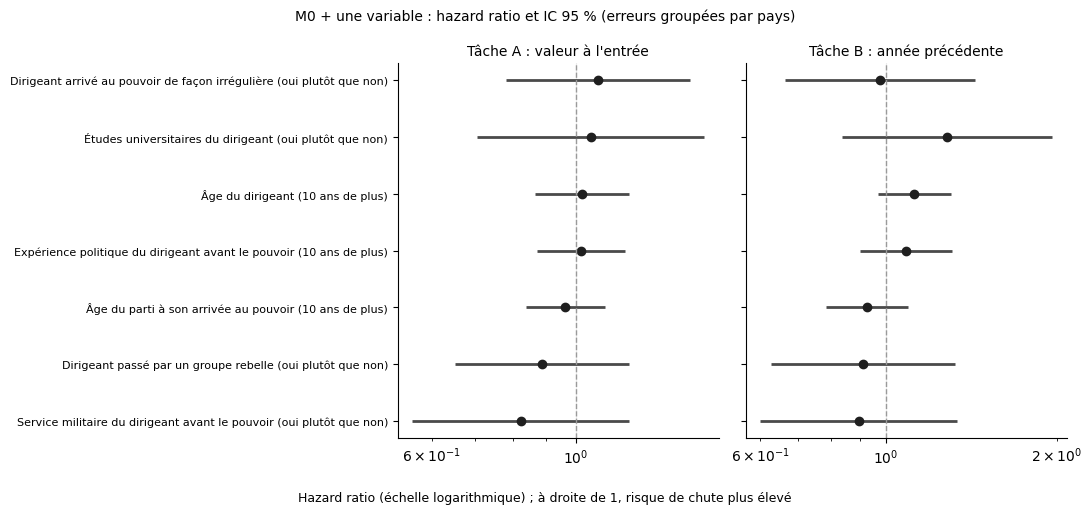

In [13]:
# ============================================================
# 6.4 Graphique : hazard ratio de chaque variable dans P2 (Tâches A et B)
# ============================================================
order = combined.sort_values("A HR").index
fig, axes = plt.subplots(1, 2, figsize=(11, 0.5 * len(order) + 1.6), sharey=True)
y = np.arange(len(order))
for ax, task, title in ((axes[0], "A", "Tâche A : valeur à l'entrée"), (axes[1], "B", "Tâche B : année précédente")):
    ax.hlines(y, combined.loc[order, f"{task} IC bas"], combined.loc[order, f"{task} IC haut"], color="#4a4a4a", linewidth=2)
    ax.plot(combined.loc[order, f"{task} HR"], y, "o", color="#1f1f1f", markersize=6)
    ax.axvline(1, color="#9a9a9a", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_yticks(y, [f"{LABEL[v]} ({UNIT[v]})" for v in order], fontsize=8)
fig.supxlabel("Hazard ratio (échelle logarithmique) ; à droite de 1, risque de chute plus élevé", fontsize=9)
fig.suptitle("M0 + une variable : hazard ratio et IC 95 % (erreurs groupées par pays)", fontsize=10)
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# 6.5 Variables non testables : estimations descriptives (hors règles de décision)
# ============================================================
REDUCED_TV = ["log_gdppc_lag1", "polity2_lag1"]          # modèle réduit de la Tâche B (Section 5)
DESC_COLS = ["unité", "partis (A)", "chutes (A)", "parti-années (B)", "chutes (B)", "HR (A, M0 + variable)",
             "IC bas (A, M0 + variable)", "IC haut (A, M0 + variable)", "p (A, M0 + variable)", "HR (B, réduit)",
             "IC bas (B, réduit)", "IC haut (B, réduit)", "p (B, réduit)"]
desc_rows = []
for v in UNTESTABLE:
    da, dt = MS.dropna(subset=SF + [v]), MT.dropna(subset=TF + [v])
    row = {"variable": v, "unité": UNIT[v], "partis (A)": len(da), "chutes (A)": int(da["event"].sum()),
           "parti-années (B)": len(dt), "chutes (B)": int(dt["event"].sum())}
    if len(da) and epp(da, len(SF) + 1) >= MIN_EPP:
        row.update({f"{k} (A, M0 + variable)": x for k, x in hr_of(fit_static(da, SF + [v]), v).items() if k != "coef"})
    dr = MT.dropna(subset=REDUCED_TV + [v])
    if len(dr) and epp(dr, len(REDUCED_TV) + 1) >= MIN_EPP:
        row.update({f"{k} (B, réduit)": x for k, x in hr_of(fit_cluster(dr, [v] + REDUCED_TV), v).items() if k != "coef"})
    desc_rows.append(row)
descriptive = pd.DataFrame(desc_rows, columns=["variable"] + DESC_COLS).set_index("variable")
if UNTESTABLE:
    display(Markdown("**Variables non testables** — estimations descriptives, erreurs groupées par pays ; elles ne "
                     "comptent pas dans la décision :"))
    display(descriptive.round(3))
else:
    print("Toutes les variables sont testables.")

Toutes les variables sont testables.


## 7. Validation croisée (prédiction)

Le moteur d'évaluation est celui de `04_demographics.ipynb` (Section 7.1), dans les deux tâches. Avant toute comparaison, il est vérifié : appliqué à M0 sur l'échantillon complet, il doit retrouver **exactement** les scores enregistrés par `03_ml_survival.ipynb` pour les modèles de Cox, pli par pli. Les 50 plis sont calculés en parallèle ; chaque calcul est déterministe.

In [15]:
# ============================================================
# 7.1 Moteur d'évaluation (Tâche A : survie par parti ; Tâche B : hasard annuel)
# ============================================================
FOLDS = pd.read_csv(PROC / "ml_folds.csv", dtype={"row_id": str})
FOLDS_A = FOLDS.query("dataset == 'static'")
FOLDS_B = FOLDS.query("dataset == 'timevarying'").astype({"row_id": int})
WEIGHTS = np.round(np.linspace(0, 1, 11), 1)


def fold_assignment(df, rep, task):
    folds = FOLDS_A if task == "A" else FOLDS_B
    key = df["spell_id"] if task == "A" else df["row_id"]
    return folds[folds["repetition"] == rep].set_index("row_id").loc[key, "fold"].to_numpy()


def inner_splits(train):
    return list(StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=RANDOM_STATE)
                .split(train, train["event"], train["Country"]))


def usable(train, feats):
    return [c for c in feats if train[c].var() > 0]     # une covariable constante ne peut pas être estimée


def cox_fit(train, feats):
    return CoxPHFitter(penalizer=PENALIZER).fit(train[["duration", "event"] + feats], "duration", "event")


def ctv_probability(model, train, test, feats):
    """Probabilités annuelles du Cox time-varying, hasard de base constant par classe de durée (03, 4.2)."""
    risk = model.predict_partial_hazard(train[feats]).to_numpy()
    bins = train["time_bin_code"].to_numpy()
    h0 = pd.Series(train["event"].to_numpy()).groupby(bins).sum() / pd.Series(risk).groupby(bins).sum()
    h = h0.reindex(test["time_bin_code"].to_numpy()).to_numpy()
    assert not np.isnan(h).any(), "classe de durée absente du pli d'apprentissage"
    return 1 - np.exp(-h * model.predict_partial_hazard(test[feats]).to_numpy())


def blend_weight_A(train, f0, f1):
    """Poids du mélange choisi dans le pli d'apprentissage : C de Harrell moyen sur 3 plis internes."""
    score = np.zeros(len(WEIGHTS))
    for i_tr, i_va in inner_splits(train):
        tr, va = train.iloc[i_tr], train.iloc[i_va]
        lp = [cox_fit(tr, usable(tr, f)).predict_log_partial_hazard(va[usable(tr, f)]).to_numpy() for f in (f0, f1)]
        for j, w in enumerate(WEIGHTS):
            score[j] += concordance_index_censored(va["event"].astype(bool), va["duration"], (1 - w) * lp[0] + w * lp[1])[0]
    return float(WEIGHTS[int(np.argmax(score))])


def blend_weight_B(train, f0, f1):
    """Poids du mélange choisi dans le pli d'apprentissage : perte logarithmique moyenne sur 3 plis internes."""
    score = np.zeros(len(WEIGHTS))
    for i_tr, i_va in inner_splits(train):
        tr, va = train.iloc[i_tr], train.iloc[i_va]
        p = [ctv_probability(fit_tv(tr, usable(tr, f)), tr, va, usable(tr, f)) for f in (f0, f1)]
        for j, w in enumerate(WEIGHTS):
            score[j] += log_loss(va["event"], (1 - w) * p[0] + w * p[1], labels=[0, 1])
    return float(WEIGHTS[int(np.argmin(score))])


def brier_A(y_tr, y_te, surv, grid, test_time, train_max):
    """Score de Brier intégré ; un parti de test plus long que le plus long parti d'apprentissage est exclu de ce
    score seulement (04_demographics.ipynb, Section 7)."""
    if len(grid) < 2:
        return np.nan, 0
    try:
        return integrated_brier_score(y_tr, y_te, surv, grid), 0
    except ValueError as err:
        if "largest observed time point" not in str(err):
            raise
    keep = test_time <= train_max
    on_grid = grid < test_time[keep].max()
    return integrated_brier_score(y_tr, y_te[keep], surv[keep][:, on_grid], grid[on_grid]), int((~keep).sum())


def fold_A(df, assignment, rep, k, models, blends):
    warnings.filterwarnings("ignore")
    train, test = df[assignment != k], df[assignment == k]
    y_tr = Surv.from_arrays(event=train["event"].astype(bool), time=train["duration"])
    y_te = Surv.from_arrays(event=test["event"].astype(bool), time=test["duration"])
    tau = float(np.percentile(train["duration"], 80))
    grid = np.arange(max(1, int(np.ceil(test["duration"].min()))), int(min(test["duration"].max(), train["duration"].max())))
    preds = {}
    for name, feats in models.items():
        f = usable(train, feats)
        m = cox_fit(train, f)
        preds[name] = (m.predict_log_partial_hazard(test[f]).to_numpy(),
                       m.predict_survival_function(test[f], times=grid).to_numpy().T, np.nan)
    for name, base, other in blends:
        w = blend_weight_A(train, models[base], models[other])
        preds[name] = ((1 - w) * preds[base][0] + w * preds[other][0], (1 - w) * preds[base][1] + w * preds[other][1], w)
    rows = []
    for name, (lp, surv, w) in preds.items():
        ibs, excluded = brier_A(y_tr, y_te, surv, grid, test["duration"].to_numpy(), train["duration"].max())
        rows.append({"model": name, "repetition": rep, "fold": k, "n_train": len(train), "n_test": len(test),
                     "events_test": int(test["event"].sum()), "censored_test": int((test["event"] == 0).sum()),
                     "harrell_c": concordance_index_censored(y_te["event"], y_te["time"], lp)[0],
                     "uno_c": concordance_index_ipcw(y_tr, y_te, lp, tau=tau)[0],
                     "ibs": ibs, "ibs_excluded": excluded, "weight": w})
    return rows


def fold_B(df, assignment, rep, k, models, blends):
    warnings.filterwarnings("ignore")
    train, test = df[assignment != k], df[assignment == k]
    preds = {}
    for name, feats in models.items():
        f = usable(train, feats)
        preds[name] = (ctv_probability(fit_tv(train, f), train, test, f), np.nan)
    for name, base, other in blends:
        w = blend_weight_B(train, models[base], models[other])
        preds[name] = ((1 - w) * preds[base][0] + w * preds[other][0], w)
    return [{"model": name, "repetition": rep, "fold": k, "n_train": len(train), "n_test": len(test),
             "events_test": int(test["event"].sum()), "event_rate": float(test["event"].mean()),
             "roc_auc": roc_auc_score(test["event"], p), "pr_auc": average_precision_score(test["event"], p),
             "brier": brier_score_loss(test["event"], p), "log_loss": log_loss(test["event"], p, labels=[0, 1]),
             "weight": w} for name, (p, w) in preds.items()]


def evaluate(task, df, models, blends=(), comparison=""):
    """Les 50 plis (5 plis x 10 répétitions) en parallèle ; une ligne par modèle et par pli."""
    df = df.reset_index(drop=True)
    assignments = {rep: fold_assignment(df, rep, task) for rep in range(N_REPEATS)}
    worker = fold_A if task == "A" else fold_B
    out = Parallel(n_jobs=-1)(delayed(worker)(df, assignments[rep], rep, k, models, blends)
                              for rep in range(N_REPEATS) for k in range(N_FOLDS))
    return pd.DataFrame([r for rows in out for r in rows]).assign(comparison=comparison)

In [16]:
# ============================================================
# 7.2 Vérification : M0 sur l'échantillon complet retrouve les scores de 03_ml_survival.ipynb
# ============================================================
start = time.perf_counter()
check_A = evaluate("A", MS, {"M0": SF})
check_B = evaluate("B", MT, {"M0": TF})
ref_A = pd.read_csv(PROC / "ml_results_taskA.csv").query("model == 'Cox'").set_index(["repetition", "fold"])
ref_B = pd.read_csv(PROC / "ml_results_taskB.csv").query("model == 'Cox time-varying'").set_index(["repetition", "fold"])
gaps = {}
for check, ref, metrics in [(check_A, ref_A, ["harrell_c", "uno_c", "ibs"]),
                            (check_B, ref_B, ["roc_auc", "pr_auc", "brier", "log_loss"])]:
    mine = check.set_index(["repetition", "fold"]).loc[ref.index]
    for m in metrics:
        gaps[m] = float((mine[m] - ref[m]).abs().max())
assert max(gaps.values()) < 1e-9, gaps
display(Markdown(
    f"**Vérification réussie** ({time.perf_counter() - start:.0f} s). Sur l'échantillon complet, le moteur retrouve, "
    f"pli par pli, les scores des modèles de Cox de `03_ml_survival.ipynb` (écart maximal {max(gaps.values()):.1e}) : "
    f"C de Harrell {ref_A['harrell_c'].mean():.3f}, ROC-AUC {ref_B['roc_auc'].mean():.3f} en moyenne sur 50 plis."))

**Vérification réussie** (10 s). Sur l'échantillon complet, le moteur retrouve, pli par pli, les scores des modèles de Cox de `03_ml_survival.ipynb` (écart maximal 9.7e-17) : C de Harrell 0.616, ROC-AUC 0.673 en moyenne sur 50 plis.

In [17]:
# ============================================================
# 7.3 Comparaison sur les échantillons communs (Tâches A et B)
# ============================================================
def comparison_models(task):
    base = SF if task == "A" else TF
    models = {"M0": base, "P1": CAND, **{f"P2·{v}": base + [v] for v in CAND},
              **{f"P2c·{v}": base + [v] + CONTROLS[task] for v in CAND}}
    return models, [("P3", "M0", "P1")]


start = time.perf_counter()
COMPARISON = "partis et dirigeants"
cv_A = evaluate("A", SA_M, *comparison_models("A"), comparison=COMPARISON)
cv_B = evaluate("B", TB_M, *comparison_models("B"), comparison=COMPARISON)
excluded = int(cv_A.loc[cv_A["model"] == "M0", "ibs_excluded"].sum())
print(f"Validation croisée : {(time.perf_counter() - start) / 60:.1f} min "
      f"({cv_A['model'].nunique() + cv_B['model'].nunique()} modèles x 50 plis) ; partis de test exclus du score de "
      f"Brier intégré (total sur 50 plis) : {excluded}")

Validation croisée : 1.3 min (34 modèles x 50 plis) ; partis de test exclus du score de Brier intégré (total sur 50 plis) : 2


In [18]:
# ============================================================
# 7.4 Scores moyens et tests appariés contre M0
# ============================================================
METRICS = {"A": {"harrell_c": ("C de Harrell", True), "uno_c": ("C d'Uno", True), "ibs": ("Brier intégré", False)},
           "B": {"roc_auc": ("ROC-AUC", True), "pr_auc": ("PR-AUC", True), "brier": ("Brier", False),
                 "log_loss": ("Perte log.", False)}}
PRIMARY = {"A": ("harrell_c", "ibs"), "B": ("roc_auc", "log_loss")}


def corrected_ttest(d, n_train, n_test):
    """Test t rééchantillonné corrigé (Nadeau & Bengio, 2003) pour des différences appariées."""
    J = len(d)
    t_stat = d.mean() / np.sqrt((1 / J + n_test / n_train) * d.var(ddof=1))
    return t_stat, 2 * stats.t.sf(abs(t_stat), df=J - 1)


def compare(cv, task):
    rows = []
    for comp, d in cv.groupby("comparison", sort=False):
        ref = d[d["model"] == "M0"].set_index(["repetition", "fold"])
        n_train, n_test = d["n_train"].mean(), d["n_test"].mean()
        for model in d["model"].unique():
            m = d[d["model"] == model].set_index(["repetition", "fold"])
            assert (m["n_test"] == ref["n_test"]).all(), f"{comp} / {model} : plis différents de M0"
            row = {"comparaison": comp, "modèle": model}
            for metric, (label, _) in METRICS[task].items():
                row[label] = f"{m[metric].mean():.3f} ± {m[metric].std():.3f}"
                if model != "M0":
                    diff = (m[metric] - ref[metric]).dropna()
                    _, p = corrected_ttest(diff, n_train, n_test)
                    row[f"{label} : écart"] = diff.mean()
                    row[f"{label} : p corrigée"] = p
            if model != "M0":
                disc, prob = PRIMARY[task]
                dl, pl = METRICS[task][disc][0], METRICS[task][prob][0]
                better = row[f"{dl} : p corrigée"] < ALPHA and row[f"{dl} : écart"] > 0
                worse_prob = row[f"{pl} : p corrigée"] < ALPHA and row[f"{pl} : écart"] > 0
                worse = row[f"{dl} : p corrigée"] < ALPHA and row[f"{dl} : écart"] < 0
                row["verdict"] = ("meilleur que M0" if better and not worse_prob else
                                  "moins bon que M0" if worse else "pas de différence nette")
                if not np.isnan(m["weight"]).all():
                    row["poids moyen du bloc"] = m["weight"].mean()
            else:
                row["verdict"] = "référence"
            rows.append(row)
    return pd.DataFrame(rows)


tests_A, tests_B = compare(cv_A, "A"), compare(cv_B, "B")
display(Markdown(f"**Tâche A** (survie par parti ; M0 sur l'échantillon complet de `03_ml_survival.ipynb` : C de Harrell "
                 f"{ref_A['harrell_c'].mean():.3f} ± {ref_A['harrell_c'].std():.3f}) :"))
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(tests_A.round(4))
display(Markdown(f"**Tâche B** (hasard annuel ; M0 sur l'échantillon complet : ROC-AUC {ref_B['roc_auc'].mean():.3f} "
                 f"± {ref_B['roc_auc'].std():.3f}) :"))
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(tests_B.round(4))

**Tâche A** (survie par parti ; M0 sur l'échantillon complet de `03_ml_survival.ipynb` : C de Harrell 0.616 ± 0.043) :

,comparaison,modèle,C de Harrell,C d'Uno,Brier intégré,verdict,C de Harrell : écart,C de Harrell : p corrigée,C d'Uno : écart,C d'Uno : p corrigée,Brier intégré : écart,Brier intégré : p corrigée,poids moyen du bloc
0,partis et dirigeants,M0,0.613 ± 0.056,0.612 ± 0.057,0.167 ± 0.031,référence,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,partis et dirigeants,P1,0.545 ± 0.055,0.544 ± 0.057,0.180 ± 0.033,pas de différence nette,-0.0680,0.0782,-0.0676,0.0831,0.0129,0.2283,NaN
2,partis et dirigeants,P2·party_age,0.607 ± 0.056,0.606 ± 0.058,0.168 ± 0.032,pas de différence nette,-0.0058,0.5123,-0.0062,0.5063,0.0016,0.3543,NaN
3,partis et dirigeants,P2·leader_age,0.604 ± 0.053,0.603 ± 0.054,0.168 ± 0.032,pas de différence nette,-0.0085,0.2044,-0.0088,0.2077,0.0013,0.2658,NaN
4,partis et dirigeants,P2·leader_irregular,0.609 ± 0.057,0.608 ± 0.058,0.168 ± 0.031,pas de différence nette,-0.0043,0.4741,-0.0038,0.5214,0.0011,0.2042,NaN
5,partis et dirigeants,P2·leader_military,0.616 ± 0.055,0.616 ± 0.057,0.167 ± 0.031,pas de différence nette,0.0031,0.6311,0.0037,0.5854,0.0007,0.7135,NaN
6,partis et dirigeants,P2·leader_rebel,0.614 ± 0.055,0.614 ± 0.056,0.167 ± 0.031,pas de différence nette,0.0015,0.8161,0.0018,0.7939,0.0006,0.5991,NaN
7,partis et dirigeants,P2·leader_university,0.609 ± 0.057,0.609 ± 0.058,0.169 ± 0.032,pas de différence nette,-0.0035,0.4982,-0.0031,0.5615,0.0018,0.2062,NaN
8,partis et dirigeants,P2·leader_experience,0.608 ± 0.054,0.607 ± 0.055,0.168 ± 0.031,pas de différence nette,-0.0044,0.4710,-0.0051,0.4189,0.0010,0.3454,NaN
9,partis et dirigeants,P2c·party_age,0.602 ± 0.053,0.600 ± 0.054,0.170 ± 0.033,pas de différence nette,-0.0110,0.2203,-0.0116,0.2115,0.0033,0.2338,NaN


**Tâche B** (hasard annuel ; M0 sur l'échantillon complet : ROC-AUC 0.673 ± 0.034) :

,comparaison,modèle,ROC-AUC,PR-AUC,Brier,Perte log.,verdict,ROC-AUC : écart,ROC-AUC : p corrigée,PR-AUC : écart,PR-AUC : p corrigée,Brier : écart,Brier : p corrigée,Perte log. : écart,Perte log. : p corrigée,poids moyen du bloc
0,partis et dirigeants,M0,0.649 ± 0.038,0.116 ± 0.030,0.049 ± 0.003,0.198 ± 0.012,référence,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,partis et dirigeants,P1,0.585 ± 0.040,0.095 ± 0.026,0.049 ± 0.003,0.203 ± 0.010,moins bon que M0,-0.0637,0.0148,-0.0213,0.2385,0.0003,0.3458,0.0043,0.0512,NaN
2,partis et dirigeants,P2·party_age,0.647 ± 0.041,0.113 ± 0.029,0.049 ± 0.003,0.198 ± 0.012,pas de différence nette,-0.0015,0.8055,-0.0033,0.5185,-0.0000,0.6256,-0.0001,0.9104,NaN
3,partis et dirigeants,P2·leader_age,0.649 ± 0.038,0.117 ± 0.030,0.049 ± 0.003,0.198 ± 0.012,pas de différence nette,0.0001,0.9867,0.0009,0.9061,-0.0000,0.9357,-0.0000,0.9990,NaN
4,partis et dirigeants,P2·leader_irregular,0.646 ± 0.037,0.113 ± 0.030,0.049 ± 0.003,0.199 ± 0.012,pas de différence nette,-0.0030,0.2037,-0.0029,0.3773,0.0000,0.1604,0.0003,0.1285,NaN
5,partis et dirigeants,P2·leader_military,0.648 ± 0.040,0.115 ± 0.030,0.049 ± 0.003,0.198 ± 0.012,pas de différence nette,-0.0010,0.7195,-0.0018,0.5994,0.0000,0.5984,0.0001,0.6056,NaN
6,partis et dirigeants,P2·leader_rebel,0.649 ± 0.038,0.110 ± 0.028,0.049 ± 0.003,0.198 ± 0.012,pas de différence nette,0.0001,0.9455,-0.0060,0.4190,0.0000,0.4831,0.0001,0.7143,NaN
7,partis et dirigeants,P2·leader_university,0.649 ± 0.034,0.116 ± 0.028,0.049 ± 0.003,0.198 ± 0.011,pas de différence nette,0.0006,0.9268,-0.0002,0.9690,-0.0001,0.4513,-0.0001,0.8477,NaN
8,partis et dirigeants,P2·leader_experience,0.647 ± 0.036,0.116 ± 0.031,0.049 ± 0.004,0.199 ± 0.012,pas de différence nette,-0.0021,0.6963,-0.0004,0.9621,0.0001,0.6268,0.0004,0.6086,NaN
9,partis et dirigeants,P2c·party_age,0.644 ± 0.039,0.112 ± 0.029,0.049 ± 0.003,0.198 ± 0.012,pas de différence nette,-0.0046,0.4096,-0.0043,0.5223,-0.0000,0.9565,0.0002,0.7253,NaN


## 8. Décision et modèle final

Application des quatre conditions de la Section 5 à chaque variable testée.

In [19]:
# ============================================================
# 8.1 Décision pour chaque variable
# ============================================================
holm_p = multipletests(combined.loc[CAND, "A p"].to_numpy(), alpha=ALPHA, method="holm")[1]
ta = tests_A.set_index("modèle")
c = combined.loc[CAND]
decision = pd.DataFrame(index=CAND)
decision["source"] = [SOURCE[v] for v in CAND]
decision["unité"] = [UNIT[v] for v in CAND]
for k in ("HR", "IC bas", "IC haut", "p"):
    decision[f"{k} (A)"] = c[f"A {k}"]
decision["p Holm"] = holm_p
decision["1. Holm < 0,05"] = holm_p < ALPHA
decision["HR (B)"] = c["B HR"]
decision["p (B)"] = c["B p"]
decision["2. même sens"] = np.sign(c["A coef"]) == np.sign(c["B coef"])
decision["écart C (A)"] = [ta.loc[f"P2·{v}", "C de Harrell : écart"] for v in CAND]
decision["p corrigée C"] = [ta.loc[f"P2·{v}", "C de Harrell : p corrigée"] for v in CAND]
decision["3. C > M0"] = (decision["écart C (A)"] > 0) & (decision["p corrigée C"] < ALPHA)
decision["HR contrôlé (A)"] = c["contrôle A HR"]
decision["p contrôlé (A)"] = c["contrôle A p"]
decision["HR contrôlé (B)"] = c["contrôle B HR"]
decision["4. contrôles"] = ((np.sign(c["contrôle A coef"]) == np.sign(c["A coef"])) & (c["contrôle A p"] < ALPHA)
                           & (np.sign(c["contrôle B coef"]) == np.sign(c["A coef"])))
decision["retenue"] = decision["1. Holm < 0,05"] & decision["2. même sens"] & decision["3. C > M0"] & decision["4. contrôles"]
KEPT = decision.index[decision["retenue"]].tolist()
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(decision.round(4))


def reasons(v):
    d = decision.loc[v]
    out = []
    if not d["1. Holm < 0,05"]:
        out.append(f"p ajustée de Holm {d['p Holm']:.3f}")
    if not d["2. même sens"]:
        out.append(f"sens différent en Tâches A et B (HR {d['HR (A)']:.2f} et {d['HR (B)']:.2f})")
    if not d["3. C > M0"]:
        out.append(f"C de Harrell {d['écart C (A)']:+.4f} par rapport à M0 (p corrigée = {d['p corrigée C']:.3f})")
    if not d["4. contrôles"]:
        out.append(f"ne survit pas aux contrôles (Tâche A : HR {d['HR contrôlé (A)']:.2f}, p = {d['p contrôlé (A)']:.3f} ; "
                   f"Tâche B : HR {d['HR contrôlé (B)']:.2f})")
    return out


display(Markdown(
    f"**Variables retenues** : {', '.join(f'`{v}`' for v in KEPT) if KEPT else 'aucune'}.\n\n"
    + "\n".join(f"- `{v}` ({LABEL[v]}) : " + ("retenue" if v in KEPT else "écartée — " + " ; ".join(reasons(v)))
                for v in CAND)))

,source,unité,HR (A),IC bas (A),IC haut (A),p (A),p Holm,"1. Holm < 0,05",HR (B),p (B),2. même sens,écart C (A),p corrigée C,3. C > M0,HR contrôlé (A),p contrôlé (A),HR contrôlé (B),4. contrôles,retenue
party_age,ARPD,10 ans de plus,0.9642,0.8367,1.1112,0.6147,1.0,False,0.9258,0.3621,True,-0.0058,0.5123,False,0.9735,0.7109,0.9236,False,False
leader_age,Archigos,10 ans de plus,1.0232,0.8653,1.2098,0.7888,1.0,False,1.1226,0.1254,True,-0.0085,0.2044,False,1.0564,0.5433,1.1258,False,False
leader_irregular,Archigos,oui plutôt que non,1.0828,0.7815,1.5003,0.6324,1.0,False,0.9751,0.8983,False,-0.0043,0.4741,False,1.0350,0.8433,0.9806,False,False
leader_military,LEAD,oui plutôt que non,0.8222,0.5597,1.2078,0.3184,1.0,False,0.8944,0.5838,True,0.0031,0.6311,False,0.7996,0.2573,0.8971,False,False
leader_rebel,LEAD,oui plutôt que non,0.8871,0.6512,1.2084,0.4474,1.0,False,0.9103,0.6227,True,0.0015,0.8161,False,0.8725,0.3860,0.9144,False,False
leader_university,LEAD,oui plutôt que non,1.0550,0.7051,1.5785,0.7945,1.0,False,1.2818,0.2539,True,-0.0035,0.4982,False,1.0966,0.6597,1.2787,False,False
leader_experience,LEAD,10 ans de plus,1.0197,0.8726,1.1917,0.8060,1.0,False,1.0844,0.3936,True,-0.0044,0.4710,False,1.0337,0.6763,1.0836,False,False


**Variables retenues** : aucune.

- `party_age` (Âge du parti à son arrivée au pouvoir) : écartée — p ajustée de Holm 1.000 ; C de Harrell -0.0058 par rapport à M0 (p corrigée = 0.512) ; ne survit pas aux contrôles (Tâche A : HR 0.97, p = 0.711 ; Tâche B : HR 0.92)
- `leader_age` (Âge du dirigeant) : écartée — p ajustée de Holm 1.000 ; C de Harrell -0.0085 par rapport à M0 (p corrigée = 0.204) ; ne survit pas aux contrôles (Tâche A : HR 1.06, p = 0.543 ; Tâche B : HR 1.13)
- `leader_irregular` (Dirigeant arrivé au pouvoir de façon irrégulière) : écartée — p ajustée de Holm 1.000 ; sens différent en Tâches A et B (HR 1.08 et 0.98) ; C de Harrell -0.0043 par rapport à M0 (p corrigée = 0.474) ; ne survit pas aux contrôles (Tâche A : HR 1.04, p = 0.843 ; Tâche B : HR 0.98)
- `leader_military` (Service militaire du dirigeant avant le pouvoir) : écartée — p ajustée de Holm 1.000 ; C de Harrell +0.0031 par rapport à M0 (p corrigée = 0.631) ; ne survit pas aux contrôles (Tâche A : HR 0.80, p = 0.257 ; Tâche B : HR 0.90)
- `leader_rebel` (Dirigeant passé par un groupe rebelle) : écartée — p ajustée de Holm 1.000 ; C de Harrell +0.0015 par rapport à M0 (p corrigée = 0.816) ; ne survit pas aux contrôles (Tâche A : HR 0.87, p = 0.386 ; Tâche B : HR 0.91)
- `leader_university` (Études universitaires du dirigeant) : écartée — p ajustée de Holm 1.000 ; C de Harrell -0.0035 par rapport à M0 (p corrigée = 0.498) ; ne survit pas aux contrôles (Tâche A : HR 1.10, p = 0.660 ; Tâche B : HR 1.28)
- `leader_experience` (Expérience politique du dirigeant avant le pouvoir) : écartée — p ajustée de Holm 1.000 ; C de Harrell -0.0044 par rapport à M0 (p corrigée = 0.471) ; ne survit pas aux contrôles (Tâche A : HR 1.03, p = 0.676 ; Tâche B : HR 1.08)

In [20]:
# ============================================================
# 8.2 Modèle final F (seulement si au moins une variable est retenue)
# ============================================================
final = None
if KEPT:
    sF, tF = MS.dropna(subset=SF + KEPT), MT.dropna(subset=TF + KEPT)
    epp_F = {"A": epp(sF, len(SF) + len(KEPT)), "B": epp(tF, len(TF) + len(KEPT))}
    if min(epp_F.values()) >= MIN_EPP:
        m_a, m_b = fit_static(sF, SF + KEPT), fit_cluster(tF, TF + KEPT)
        cv_FA = evaluate("A", sF, {"M0": SF, "F": SF + KEPT}, comparison="modèle final")
        cv_FB = evaluate("B", tF, {"M0": TF, "F": TF + KEPT}, comparison="modèle final")
        cv_A, cv_B = pd.concat([cv_A, cv_FA], ignore_index=True), pd.concat([cv_B, cv_FB], ignore_index=True)
        tests_A, tests_B = compare(cv_A, "A"), compare(cv_B, "B")
        final = {"variables": KEPT, "spells": len(sF), "events": int(sF["event"].sum()), "rows_tv": len(tF),
                 "events_tv": int(tF["event"].sum()), "epp": epp_F,
                 "hazard_ratios_A": pd.DataFrame({v: hr_of(m_a, v) for v in KEPT}).T,
                 "hazard_ratios_B": pd.DataFrame({v: hr_of(m_b, v) for v in KEPT}).T}
        display(Markdown(f"**Modèle final F** : M0 + {', '.join(f'`{v}`' for v in KEPT)} ; {len(sF)} partis, "
                         f"{int(sF['event'].sum())} chutes ({epp_F['A']:.1f} chutes par paramètre)."))
        display(final["hazard_ratios_A"].round(3))
        display(tests_A[tests_A["comparaison"] == "modèle final"].round(4))
        display(tests_B[tests_B["comparaison"] == "modèle final"].round(4))
    else:
        display(Markdown(f"Le modèle final F n'est pas estimé : {min(epp_F.values()):.1f} chutes par paramètre "
                         f"(minimum {MIN_EPP})."))
else:
    display(Markdown("**Aucune variable n'est retenue** : le modèle final F n'est pas estimé, et le modèle existant reste "
                     "le modèle de référence."))

cv_A.to_csv(PROC / "leaders_cv_taskA.csv", index=False)
cv_B.to_csv(PROC / "leaders_cv_taskB.csv", index=False)
print(f"data/processed/leaders_cv_taskA.csv ({len(cv_A)} lignes) ; data/processed/leaders_cv_taskB.csv ({len(cv_B)} lignes)")

**Aucune variable n'est retenue** : le modèle final F n'est pas estimé, et le modèle existant reste le modèle de référence.

data/processed/leaders_cv_taskA.csv (850 lignes) ; data/processed/leaders_cv_taskB.csv (850 lignes)


## 9. Conclusion et limites

In [21]:
# ============================================================
# 9. Conclusion et limites (générées à partir des résultats)
# ============================================================
def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def lc(text):
    return text[:1].lower() + text[1:]


def direction(hr):
    return "plus élevé" if hr > 1 else "plus faible"


ta, tb = tests_A.set_index("modèle"), tests_B.set_index("modèle")
if KEPT:
    verdict_txt = (f"Selon les règles fixées en Section 5, {len(KEPT)} variable(s) sur {len(CAND)} apporte(nt) une "
                   f"information au-delà du modèle existant : {', '.join(lc(LABEL[v]) for v in KEPT)}.")
else:
    verdict_txt = ("**Selon les règles fixées en Section 5, aucune caractéristique du parti ou du dirigeant testée "
                   f"n'apporte d'information au-delà du modèle existant** : aucune des {len(CAND)} variables ne remplit "
                   "les quatre conditions.")
sig_raw = decision.index[decision["p (A)"] < ALPHA].tolist()
raw_txt = (f" Avant correction pour comparaisons multiples, {len(sig_raw)} variable(s) ont p < 0.05 en Tâche A ("
           + ", ".join(f"{lc(LABEL[v])} : HR {decision.loc[v, 'HR (A)']:.2f} pour {UNIT[v]}, "
                       f"{fmt_p(decision.loc[v, 'p (A)'])}" for v in sig_raw) + ")"
           if sig_raw else " Aucune variable n'a p < 0.05 en Tâche A, même avant correction")
raw_txt += f" ; la méthode de Holm porte sur {len(CAND)} variables."
closest = decision["p (A)"].idxmin()
d0 = decision.loc[closest]
raw_txt += (f" La plus proche du seuil est {lc(LABEL[closest])} : HR {d0['HR (A)']:.2f} pour {UNIT[closest]} "
            f"(IC 95 % {d0['IC bas (A)']:.2f}-{d0['IC haut (A)']:.2f}), {fmt_p(d0['p (A)'])} en Tâche A, p ajustée de "
            f"Holm {d0['p Holm']:.3f} ; en Tâche B, HR {d0['HR (B)']:.2f} ({fmt_p(d0['p (B)'])}).")

near_txt = ""
for v in CAND:
    d = decision.loc[v]
    failed = [n for n, ok in ((1, d["1. Holm < 0,05"]), (2, d["2. même sens"]), (3, d["3. C > M0"]),
                              (4, d["4. contrôles"])) if not ok]
    if v in KEPT or len(failed) != 1:
        continue
    what = {1: f"son effet ne reste pas significatif après la correction de Holm (p ajustée = {d['p Holm']:.3f})",
            2: f"son effet n'a pas le même sens en Tâche B (HR {d['HR (B)']:.2f})",
            3: (f"elle n'améliore pas nettement le C de Harrell en validation croisée ({d['écart C (A)']:+.4f}, "
                f"p corrigée = {d['p corrigée C']:.3f})"),
            4: (f"son effet ne survit pas aux contrôles (Tâche A : HR {d['HR contrôlé (A)']:.2f}, "
                f"{fmt_p(d['p contrôlé (A)'])})")}[failed[0]]
    near_txt += (f"\n\n**Presque retenue : {lc(LABEL[v])}.** Elle remplit trois des quatre conditions "
                 f"(HR {d['HR (A)']:.2f} pour {UNIT[v]}, IC 95 % {d['IC bas (A)']:.2f}-{d['IC haut (A)']:.2f}), mais "
                 f"{what}. Le risque de chute est {direction(d['HR (A)'])}, à valeurs égales des facteurs du modèle "
                 "existant : c'est une association, pas un effet.")

best_a = decision["écart C (A)"].idxmax()
pred_txt = (f"**Prédiction** — Tâche A, sur l'échantillon commun ({sample_info['spells']} partis, "
            f"{sample_info['events']} chutes) : M0 atteint un C de Harrell de {ta.loc['M0', 'C de Harrell']}. Seules, "
            f"les variables (P1) obtiennent {ta.loc['P1', 'C de Harrell']} ({ta.loc['P1', 'C de Harrell : écart']:+.3f}, "
            f"{fmt_p(ta.loc['P1', 'C de Harrell : p corrigée'])} ; {ta.loc['P1', 'verdict']}) ; mélangées à M0 (P3, poids "
            f"moyen {ta.loc['P3', 'poids moyen du bloc']:.2f} pour le bloc), {ta.loc['P3', 'C de Harrell']} "
            f"({ta.loc['P3', 'verdict']}). La variable qui améliore le plus M0 est {lc(LABEL[best_a])} "
            f"({decision.loc[best_a, 'écart C (A)']:+.4f}, p corrigée = {decision.loc[best_a, 'p corrigée C']:.3f}). "
            f"Tâche B ({sample_info['rows_tv']:,} parti-années, {sample_info['events_tv']} chutes) : ROC-AUC de M0 "
            f"{tb.loc['M0', 'ROC-AUC']}, de P1 {tb.loc['P1', 'ROC-AUC']} ({tb.loc['P1', 'verdict']}), de P3 "
            f"{tb.loc['P3', 'ROC-AUC']} ({tb.loc['P3', 'verdict']}).")

untestable_txt = ""
if UNTESTABLE:
    untestable_txt = ("**Variables non testables** : " + "; ".join(
        f"{lc(LABEL[v])} ({dropped[v] if v in dropped else removed_reason[v]})" for v in UNTESTABLE) + ".")

display(Markdown("### 9.1 Réponse\n\n" + verdict_txt + raw_txt + near_txt + "\n\n" + pred_txt
                 + ("\n\n" + untestable_txt if untestable_txt else "")))

rules = B_RULES["parti-années"].to_dict()
after = int(B_RULES.loc["après 2015", "chutes"]) if "après 2015" in B_RULES.index else 0
limits = [
    "**Qui est « le dirigeant »** : Archigos code le dirigeant effectif du pays, qui n'est pas toujours le chef du parti "
    "(roi dans une monarchie, Premier ministre ou président quand le secrétaire général du parti n'est pas codé). La "
    f"table de la Tâche A a été revue à la main ({LINK_STATS['other_leader']} dirigeants corrigés, {LINK_STATS['no_link']} "
    "partis sans lien) ; en Tâche B, le dirigeant de chaque année est celui d'Archigos, sans revue année par année.",
    f"**Couverture** : Archigos s'arrête en 2015 ({rules.get('après 2015', 0)} parti-années et {after} chutes ensuite, "
    "sans variables du dirigeant) et LEAD en 2004 : un dirigeant arrivé plus tard n'a pas de valeurs LEAD. Les "
    "échantillons communs sont donc plus anciens que l'échantillon complet.",
    "**Âge du parti** : il dépend de l'année de fondation codée par l'ARPD ; pour un parti issu d'une fusion ou d'un "
    "changement de nom, la date retenue peut être discutée.",
    "**Recoupement avec le modèle existant** : un dirigeant arrivé par un coup d'État ou passé par l'armée dirige souvent "
    "un parti d'origine militaire, un ancien rebelle un parti d'origine révolutionnaire (corrélations en Section 4.4) ; "
    "la question posée est ce que la variable ajoute au-delà de ces covariables.",
    "**Associations, pas causes** : les caractéristiques d'un dirigeant ne sont pas tirées au hasard ; un parti peut "
    "choisir un dirigeant âgé parce qu'il est déjà solide, ou un militaire parce qu'il est menacé.",
    f"**Peu de chutes** : l'échantillon commun de la Tâche A garde {sample_info['events']} chutes, soit "
    f"{sample_info['events'] / LARGEST['A']:.1f} par paramètre pour le plus grand modèle prévu ; avec la correction de "
    f"Holm sur {len(CAND)} variables, un effet modeste peut passer inaperçu.",
]
display(Markdown("### 9.2 Limites\n\n" + "\n".join(f"* {l}" for l in limits)))
display(Markdown("**Conséquence pour le site.** " + (
    "Aucune variable n'étant retenue, le modèle du site et la simulation ne changent pas." if not KEPT else
    "Le modèle du site et la simulation ne changent pas : une variable retenue décrit le parti ou son dirigeant et ne "
    "deviendra un choix de la simulation que si cela est explicitement accepté après la lecture de ces résultats.")))

### 9.1 Réponse

**Selon les règles fixées en Section 5, aucune caractéristique du parti ou du dirigeant testée n'apporte d'information au-delà du modèle existant** : aucune des 7 variables ne remplit les quatre conditions. Aucune variable n'a p < 0.05 en Tâche A, même avant correction ; la méthode de Holm porte sur 7 variables. La plus proche du seuil est service militaire du dirigeant avant le pouvoir : HR 0.82 pour oui plutôt que non (IC 95 % 0.56-1.21), p = 0.318 en Tâche A, p ajustée de Holm 1.000 ; en Tâche B, HR 0.89 (p = 0.584).

**Prédiction** — Tâche A, sur l'échantillon commun (175 partis, 152 chutes) : M0 atteint un C de Harrell de 0.613 ± 0.056. Seules, les variables (P1) obtiennent 0.545 ± 0.055 (-0.068, p = 0.078 ; pas de différence nette) ; mélangées à M0 (P3, poids moyen 0.20 pour le bloc), 0.600 ± 0.054 (pas de différence nette). La variable qui améliore le plus M0 est service militaire du dirigeant avant le pouvoir (+0.0031, p corrigée = 0.631). Tâche B (3,064 parti-années, 159 chutes) : ROC-AUC de M0 0.649 ± 0.038, de P1 0.585 ± 0.040 (moins bon que M0), de P3 0.639 ± 0.038 (pas de différence nette).

### 9.2 Limites

* **Qui est « le dirigeant »** : Archigos code le dirigeant effectif du pays, qui n'est pas toujours le chef du parti (roi dans une monarchie, Premier ministre ou président quand le secrétaire général du parti n'est pas codé). La table de la Tâche A a été revue à la main (9 dirigeants corrigés, 6 partis sans lien) ; en Tâche B, le dirigeant de chaque année est celui d'Archigos, sans revue année par année.
* **Couverture** : Archigos s'arrête en 2015 (285 parti-années et 15 chutes ensuite, sans variables du dirigeant) et LEAD en 2004 : un dirigeant arrivé plus tard n'a pas de valeurs LEAD. Les échantillons communs sont donc plus anciens que l'échantillon complet.
* **Âge du parti** : il dépend de l'année de fondation codée par l'ARPD ; pour un parti issu d'une fusion ou d'un changement de nom, la date retenue peut être discutée.
* **Recoupement avec le modèle existant** : un dirigeant arrivé par un coup d'État ou passé par l'armée dirige souvent un parti d'origine militaire, un ancien rebelle un parti d'origine révolutionnaire (corrélations en Section 4.4) ; la question posée est ce que la variable ajoute au-delà de ces covariables.
* **Associations, pas causes** : les caractéristiques d'un dirigeant ne sont pas tirées au hasard ; un parti peut choisir un dirigeant âgé parce qu'il est déjà solide, ou un militaire parce qu'il est menacé.
* **Peu de chutes** : l'échantillon commun de la Tâche A garde 152 chutes, soit 10.1 par paramètre pour le plus grand modèle prévu ; avec la correction de Holm sur 7 variables, un effet modeste peut passer inaperçu.

**Conséquence pour le site.** Aucune variable n'étant retenue, le modèle du site et la simulation ne changent pas.

## 10. Export des résultats

Les résultats sont écrits dans `data/processed/site_results_leaders.json`, avec la même structure que les autres exports (tableaux au format « split » de pandas). Le site les lit (page Analyse, carte « Le parti et son dirigeant comptent-ils ? ») ; ses textes en français, en anglais et en arabe sont construits à partir de ces chiffres par `src/site_text.py` (`leaders_texts`). L'export ne contient que des tableaux de résultats : aucune valeur pays-année, aucune valeur dirigeant par dirigeant, aucune valeur de LEAD. Le modèle du site et la simulation ne changent pas.

In [22]:
# ============================================================
# 10. Export (data/processed/site_results_leaders.json)
# ============================================================
from site_text import leaders_texts      # textes du site en français, anglais et arabe


def metric_summary(cv, task):
    out = []
    for (comp, model), d in cv.groupby(["comparison", "model"], sort=False):
        out.append({"comparison": comp, "model": model,
                    **{m: {"mean": float(d[m].mean()), "sd": float(d[m].std())} for m in METRICS[task]}})
    return out


site_leaders = {
    "source": "notebooks/06_party_leaders.ipynb",
    "created": date.today().isoformat(),
    "protocol": {"folds": N_FOLDS, "repeats": N_REPEATS, "evaluations": N_FOLDS * N_REPEATS, "grouped_by": "Country",
                 "folds_file": "data/processed/ml_folds.csv", "inner_folds": N_INNER, "blend_weights": list(WEIGHTS),
                 "min_falls": MIN_FALLS, "min_events_per_parameter": MIN_EPP, "largest_model_parameters": LARGEST,
                 "alpha": ALPHA, "multiple_testing": "holm",
                 "test": "test t rééchantillonné corrigé (Nadeau & Bengio, 2003)", "standard_errors": "groupées par pays",
                 "controls": CONTROLS, "decade_entry": "(année d'entrée - 2000) / 10", "period": "(année - 2000) / 10",
                 "archigos_last_year": ARCHIGOS_LAST_YEAR, "ph_cut": CUT, "rules_written": RULES_WRITTEN,
                 "rules_approved": RULES_APPROVED, "reduced_tv_model": REDUCED_TV},
    "sources": [{"file": n, **{k: log[n][k] for k in ("url", "downloaded", "bytes", "sha256", "version", "licence")}}
                for n in ("LEAD.rda", "arch_annual.csv")] + [{"file": "arpd_leaders_archigos.csv",
                                                               "reviewed": RULES_APPROVED}],
    "sources_not_used": log["sources_non_utilisées"],
    "links": LINK_STATS,
    "totals": {"spells": len(static), "events": int(static["event"].sum()), "rows_tv": len(tv),
               "events_tv": int(tv["event"].sum())},
    "candidates": candidates_table,
    "coverage": coverage.reset_index(),
    "task_b_leader_rules": B_RULES.reset_index(),
    "screening": {"dropped": dropped, "removed_for_sample": removed_for_sample, "removed_reason": removed_reason,
                  "retained": CAND},
    "sample": sample_info,
    "correlations": corr_table.reset_index(),
    "vif": vif_table.rename("VIF").reset_index(),
    "events_per_parameter": planned,
    "coef_check_max_gap": COEF_GAP,
    "models": {"combined": combined.reset_index(), "proportional_hazards": ph_table.reset_index(),
               "early_late": early_late, "block": block_models, "descriptive": descriptive.reset_index()},
    "cv": {"task_a": {"metrics": metric_summary(cv_A, "A"), "tests": tests_A},
           "task_b": {"metrics": metric_summary(cv_B, "B"), "tests": tests_B},
           "full_sample_m0": {"harrell_c": {"mean": float(ref_A["harrell_c"].mean()), "sd": float(ref_A["harrell_c"].std())},
                              "roc_auc": {"mean": float(ref_B["roc_auc"].mean()), "sd": float(ref_B["roc_auc"].std())}}},
    "decision": decision.reset_index().rename(columns={"index": "variable"}),
    "kept": KEPT,
    "final_model": final,
}
site_leaders["texts"] = leaders_texts(site_leaders)
size_kb = write_json(PROC / "site_results_leaders.json", site_leaders)
print(f"data/processed/site_results_leaders.json : {size_kb:.0f} Ko")

data/processed/site_results_leaders.json : 69 Ko


## 11. Références

**Données.**
- **Bolt, J., & van Zanden, J. L.** (2024). Maddison-style estimates of the evolution of the world economy: A new 2023 update. *Journal of Economic Surveys*, 39(2), 631–671. https://doi.org/10.1111/joes.12618
- **Ellis, C. M., Horowitz, M. C., & Stam, A. C.** (2015). Introducing the LEAD Data Set. *International Interactions*, 41(4), 718–741. https://doi.org/10.1080/03050629.2015.1016157
- **Goemans, H. E., Gleditsch, K. S., & Chiozza, G.** (2009). Introducing Archigos: A Data Set of Political Leaders. *Journal of Peace Research*, 46(2), 269–283 ; version 4.1. https://www.rochester.edu/college/faculty/hgoemans/data.htm
- **Miller, M. K.** (2020). The Autocratic Ruling Parties Dataset: Origins, Durability, and Death. *Journal of Conflict Resolution*, 64(4), 756–782.
- **Miller, S. V.** (2022). peacesciencer: An R Package for Quantitative Peace Science Research. *Conflict Management and Peace Science*, 39(6), 755–779 ; dépôt https://github.com/svmiller/peacesciencer

**Méthodes et concepts.**
- **Besley, T., Montalvo, J. G., & Reynal-Querol, M.** (2011). Do Educated Leaders Matter? *The Economic Journal*, 121(554), F205–F227.
- **Geddes, B.** (1999). What Do We Know About Democratization After Twenty Years? *Annual Review of Political Science*, 2, 115–144.
- **Holm, S.** (1979). A Simple Sequentially Rejective Multiple Test Procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.
- **Horowitz, M. C., Stam, A. C., & Ellis, C. M.** (2015). *Why Leaders Fight*. Cambridge University Press.
- **Levitsky, S., & Way, L. A.** (2013). The Durability of Revolutionary Regimes. *Journal of Democracy*, 24(3), 5–17.
- **Nadeau, C., & Bengio, Y.** (2003). Inference for the Generalization Error. *Machine Learning*, 52(3), 239–281.